# Analiza i wizualizacja meczu euro 2020 Szwecja - Polska

## Pozyskanie danych event po evencie

In [1]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

merged_events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


## Dodanie kolumn z lokalizacją eventów

In [2]:
from dataframe_modify.add_positions import add_positions

merged_events = add_positions(merged_events)

## Podział na sekwencje

In [3]:
from sequences.get_sequences import get_sequences_by_possession
sequences = get_sequences_by_possession(merged_events)
sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,possession_team_id,player_id,under_pressure,off_camera,counterpress,out,start_x,start_y,end_x,end_y
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,790,5617.0,,,,,60.0,40.0,36.1,39.7
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.1,39.7,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.1,39.7,36.8,41.1
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.8,41.1,49.8,68.1
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,790,5612.0,,,,,49.8,68.1,,
5,a3c476e1-a372-492d-bf5b-4ebe5a98d21c,10,1,00:00:05.863,0,5,Pass,2,Sweden,From Kick Off,...,790,5612.0,,,,,49.8,68.1,95.3,38.1
6,2b8824d2-8f34-436b-9bce-f8960a0f9cbf,11,1,00:00:09.353,0,9,Ball Receipt*,2,Sweden,From Kick Off,...,790,8552.0,,,,,95.3,38.1,,
7,baca1749-3f13-4fd4-8c1e-a84748f80a5d,12,1,00:00:09.353,0,9,Duel,2,Sweden,From Kick Off,...,790,8552.0,True,,,,95.3,38.1,,


## Ujednolicenie perspektywy lewa-prawa bramka

In [4]:
from dataframe_modify.generalize_perspective import generalize_perspective

sequences = generalize_perspective(sequences)

In [5]:
sequences[4].to_csv('test.csv')

## Dodanie stref boiska

In [6]:
from dataframe_modify.grid_areas import add_grid_areas_sequences

sequences = add_grid_areas_sequences(sequences)

sequences[0]['area_code']

0    F5D5
1      D5
2    D5D4
3    D4E2
4      E2
5    E2J5
6      J5
7      J5
Name: area_code, dtype: object

## Narysowanie pierwszych 10 sekwencji

Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00:00:29.147>


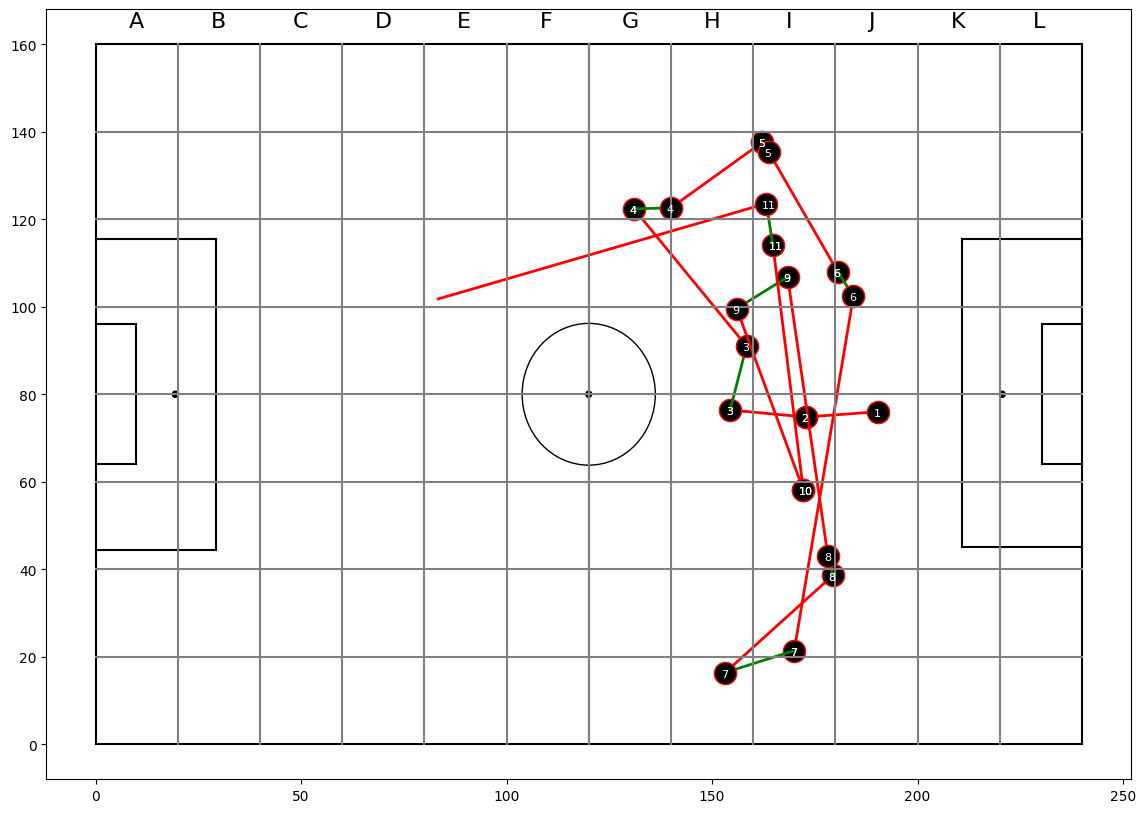

Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <00:01:20.025>

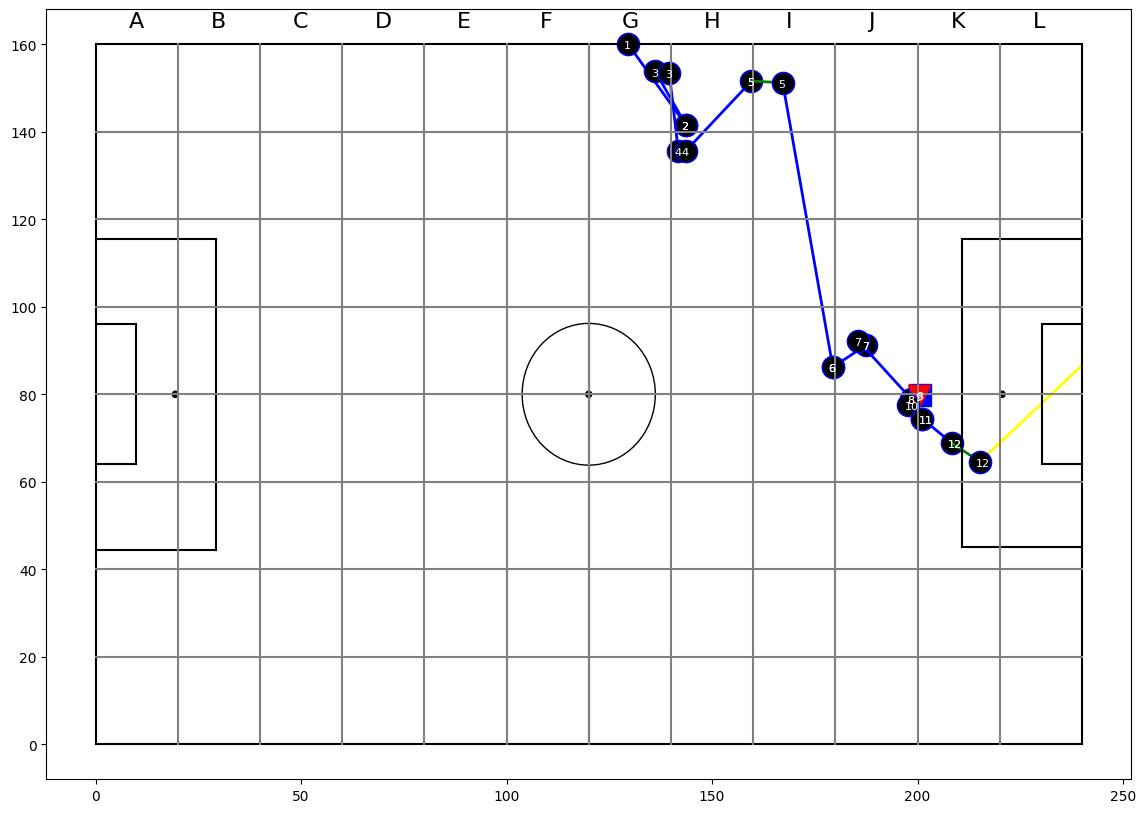

Team: Sweden
1: Mikael Lustig (Pass) <00:03:11.677>
2: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
2: Kristoffer Olsson (Pass) <00:03:12.556>
3: Mikael Lustig (Ball Receipt*) <00:03:13.491>
3: Mikael Lustig (Pass) <00:03:13.491>
4: Robin Quaison (Ball Receipt*) <00:03:16.503>
5: Kamil Glik (Pass) <00:03:16.503>
6: Tymoteusz Puchacz (Ball Receipt*) <00:03:18.134>
6: Tymoteusz Puchacz (Carry) <00:03:18.134>
6: Tymoteusz Puchacz (Pass) <00:03:19.771>
7: Marcus Andreas Danielsson (Pass) <00:03:23.681>
8: Robin Quaison (Ball Receipt*) <00:03:26.064>
9: Jan Bednarek (Duel) <00:03:26.064>
10: Robin Quaison (Pass) <00:03:26.064>
11: Emil Peter Forsberg (Ball Receipt*) <00:03:26.994>
11: Emil Peter Forsberg (Carry) <00:03:26.994>
11: Emil Peter Forsberg (Pass) <00:03:28.076>
12: Ludwig Augustinsson (Ball Receipt*) <00:03:32.879>
12: Ludwig Augustinsson (Carry) <00:03:32.879>
12: Ludwig Augustinsson (Pass) <00:03:34.011>
13: Albin Ekdal (Ball Receipt*) <00:03:35.616>
13: Albin Ekdal (Carry)

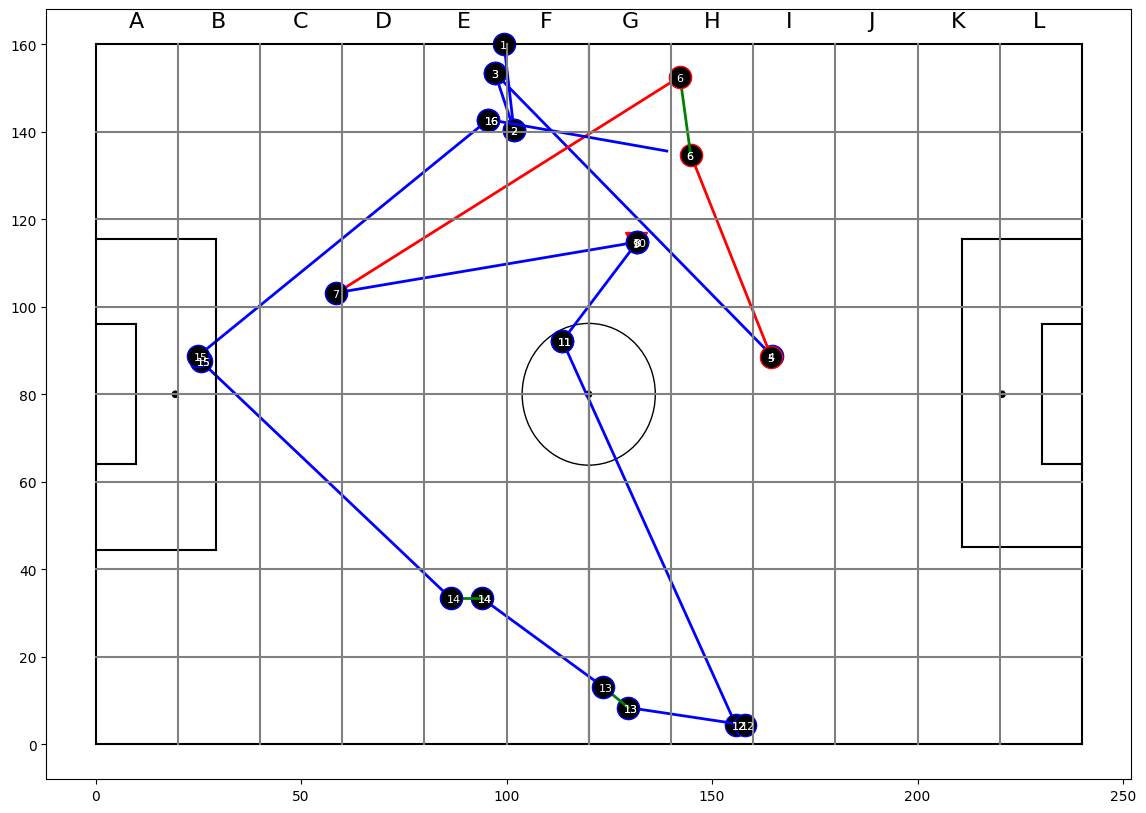

Team: Sweden
1: Kristoffer Olsson (Pass) <00:03:57.065>
2: Emil Peter Forsberg (Ball Receipt*) <00:03:58.111>
2: Emil Peter Forsberg (Carry) <00:03:58.111>
2: Emil Peter Forsberg (Pass) <00:04:01.108>
3: Ludwig Augustinsson (Ball Receipt*) <00:04:02.667>
3: Ludwig Augustinsson (Carry) <00:04:02.667>
3: Ludwig Augustinsson (Pass) <00:04:06.061>
4: Kristoffer Olsson (Ball Receipt*) <00:04:06.841>
4: Kristoffer Olsson (Carry) <00:04:06.841>
4: Kristoffer Olsson (Dispossessed) <00:04:06.879>
5: Bartosz Bereszyński (Duel) <00:04:06.879>
6: Kristoffer Olsson (Pass) <00:04:08.905>
7: Albin Ekdal (Ball Receipt*) <00:04:10.392>
7: Albin Ekdal (Pass) <00:04:10.392>
8: Ludwig Augustinsson (Ball Receipt*) <00:04:11.705>
8: Ludwig Augustinsson (Carry) <00:04:11.705>
8: Ludwig Augustinsson (Pass) <00:04:13.227>
9: Emil Peter Forsberg (Ball Receipt*) <00:04:13.915>
9: Emil Peter Forsberg (Carry) <00:04:13.915>
9: Emil Peter Forsberg (Dispossessed) <00:04:15.120>
10: Grzegorz Krychowiak (Duel) <00:04:

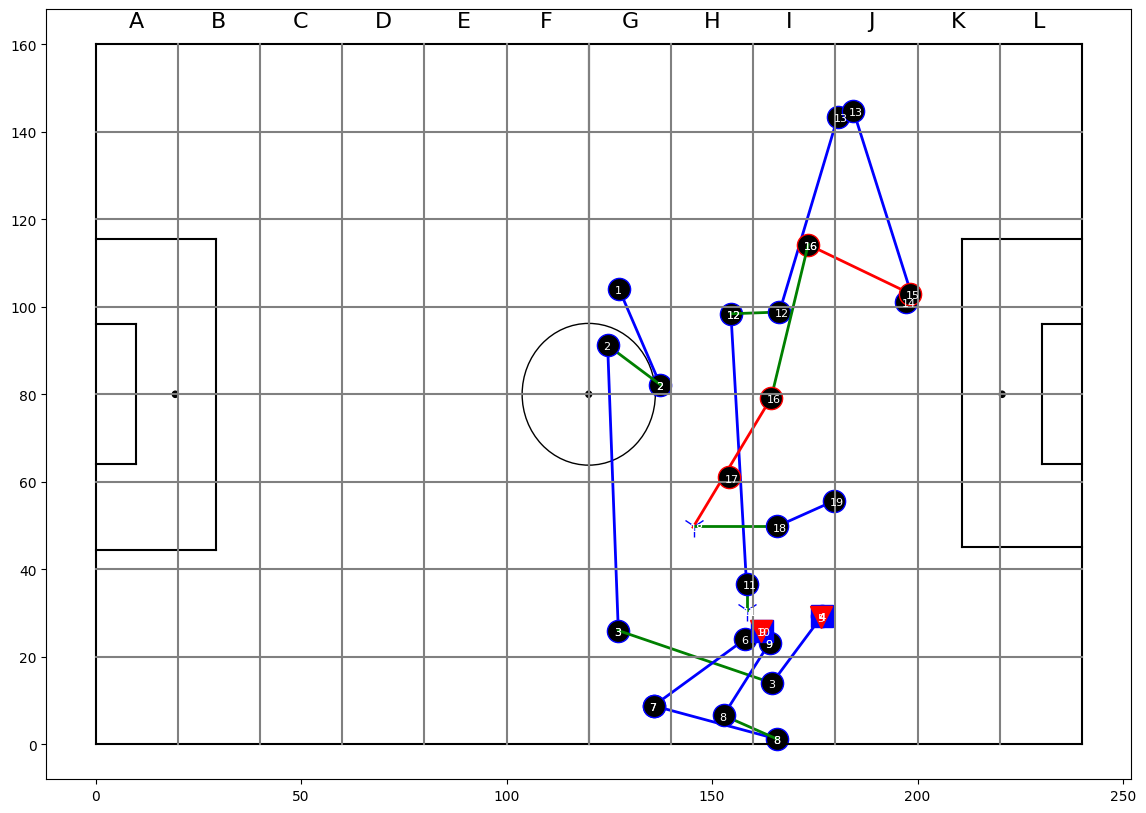

Team: Poland
1: Kamil Glik (Pass) <00:05:12.389>
2: Jan Bednarek (Ball Receipt*) <00:05:14.149>
2: Jan Bednarek (Pass) <00:05:14.172>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:05:14.736>
4: Kristoffer Olsson (Interception) <00:05:14.736>
5: Grzegorz Krychowiak (Pass) <00:05:15.315>
6: Albin Ekdal (Pass) <00:05:16.378>
7: Robin Quaison (Ball Receipt*) <00:05:19.207>
8: Jan Bednarek (Pass) <00:05:19.207>
9: Grzegorz Krychowiak (Ball Receipt*) <00:05:20.278>
9: Grzegorz Krychowiak (Pass) <00:05:20.278>
10: Mateusz Andrzej Klich (Ball Receipt*) <00:05:22.914>
10: Mateusz Andrzej Klich (Carry) <00:05:22.914>
10: Mateusz Andrzej Klich (Pass) <00:05:24.673>
11: Grzegorz Krychowiak (Ball Receipt*) <00:05:25.220>
11: Grzegorz Krychowiak (Carry) <00:05:25.220>
11: Grzegorz Krychowiak (Pass) <00:05:26.948>
12: Bartosz Bereszyński (Ball Receipt*) <00:05:27.918>
12: Bartosz Bereszyński (Carry) <00:05:27.918>
12: Bartosz Bereszyński (Pass) <00:05:29.227>
13: Karol Świderski (Ball Receipt*) <00:05

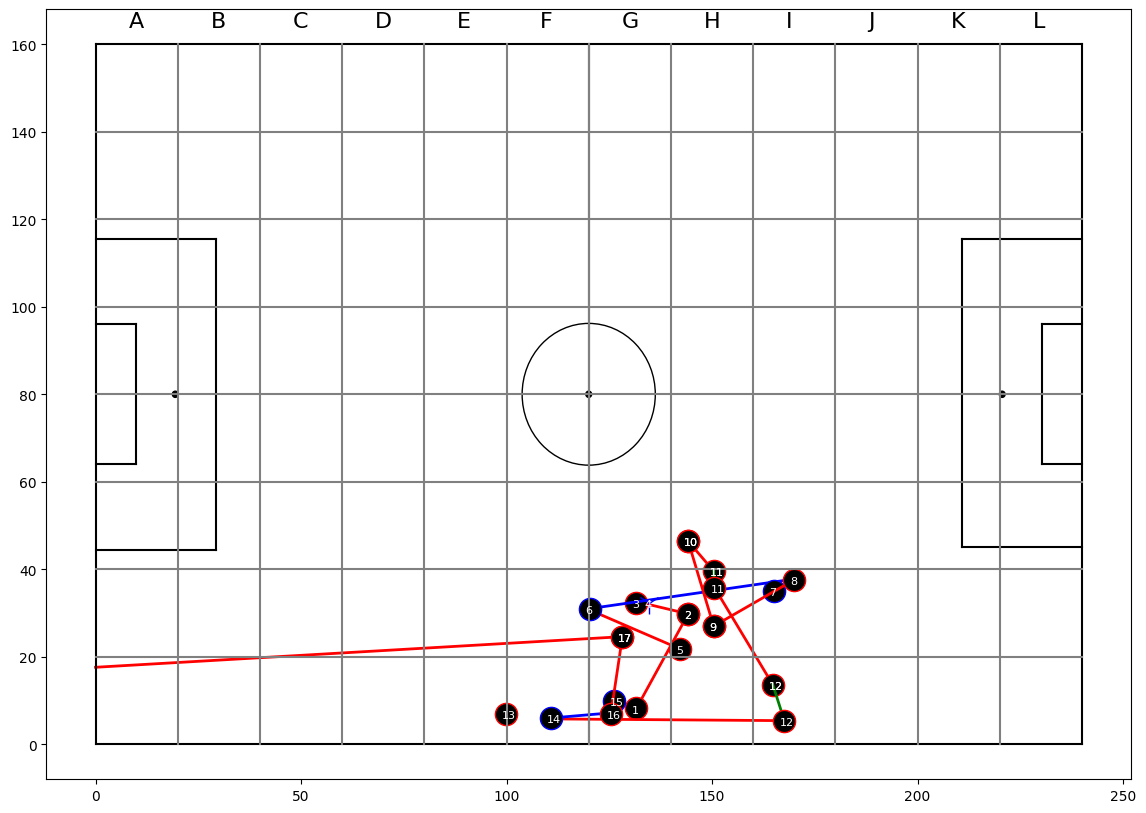

Team: Poland
1: Kamil Jóźwiak (Ball Recovery) <00:10:42.118>
1: Kamil Jóźwiak (Carry) <00:10:42.118>
1: Kamil Jóźwiak (Pass) <00:10:50.369>
2: Bartosz Bereszyński (Ball Receipt*) <00:10:51.590>
2: Bartosz Bereszyński (Carry) <00:10:51.590>
2: Bartosz Bereszyński (Pass) <00:10:52.977>
3: Kamil Glik (Ball Receipt*) <00:10:54.537>
3: Kamil Glik (Carry) <00:10:54.537>
3: Kamil Glik (Pass) <00:10:55.344>
4: Jan Bednarek (Ball Receipt*) <00:10:56.723>
4: Jan Bednarek (Carry) <00:10:56.723>
4: Jan Bednarek (Pass) <00:11:00.859>
5: Kamil Glik (Ball Receipt*) <00:11:02.511>
5: Kamil Glik (Carry) <00:11:02.511>
5: Kamil Glik (Pass) <00:11:03.540>
6: Bartosz Bereszyński (Ball Receipt*) <00:11:04.755>
6: Bartosz Bereszyński (Carry) <00:11:04.755>
6: Bartosz Bereszyński (Pass) <00:11:05.687>
7: Kamil Jóźwiak (Ball Receipt*) <00:11:07.024>
7: Kamil Jóźwiak (Carry) <00:11:07.024>
7: Kamil Jóźwiak (Pass) <00:11:09.406>
8: Piotr Zieliński (Ball Receipt*) <00:11:10.434>
8: Piotr Zieliński (Carry) <00:11

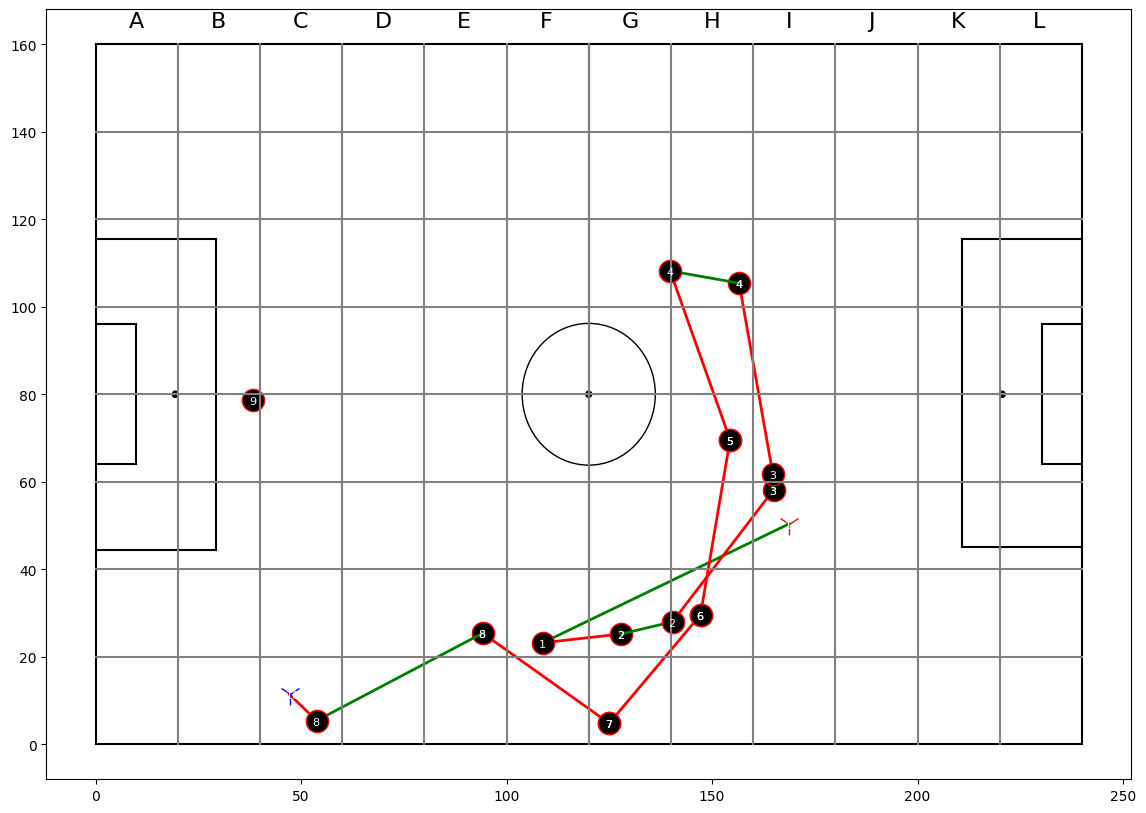

Team: Poland
1: Kamil Jóźwiak (Pass) <00:11:22.618>
2: Bartosz Bereszyński (Ball Receipt*) <00:11:24.444>
2: Bartosz Bereszyński (Carry) <00:11:24.444>
2: Bartosz Bereszyński (Pass) <00:11:25.672>
3: Kamil Glik (Ball Receipt*) <00:11:27.297>
3: Kamil Glik (Carry) <00:11:27.297>
3: Kamil Glik (Pass) <00:11:28.899>
4: Tymoteusz Puchacz (Ball Receipt*) <00:11:31.737>
4: Tymoteusz Puchacz (Carry) <00:11:31.737>
4: Tymoteusz Puchacz (Pass) <00:11:34.279>
5: Jan Bednarek (Ball Receipt*) <00:11:34.990>
5: Jan Bednarek (Carry) <00:11:34.990>
5: Jan Bednarek (Pass) <00:11:36.191>
6: Kamil Glik (Ball Receipt*) <00:11:37.713>
6: Kamil Glik (Carry) <00:11:37.713>
6: Kamil Glik (Pass) <00:11:38.972>
7: Bartosz Bereszyński (Ball Receipt*) <00:11:40.290>
7: Bartosz Bereszyński (Carry) <00:11:40.290>
7: Bartosz Bereszyński (Pass) <00:11:41.921>
8: Karol Świderski (Ball Receipt*) <00:11:43.670>
8: Karol Świderski (Pass) <00:11:43.670>
9: Robin Olsen (Ball Recovery) <00:11:48.171>
9: Robin Olsen (Carry)

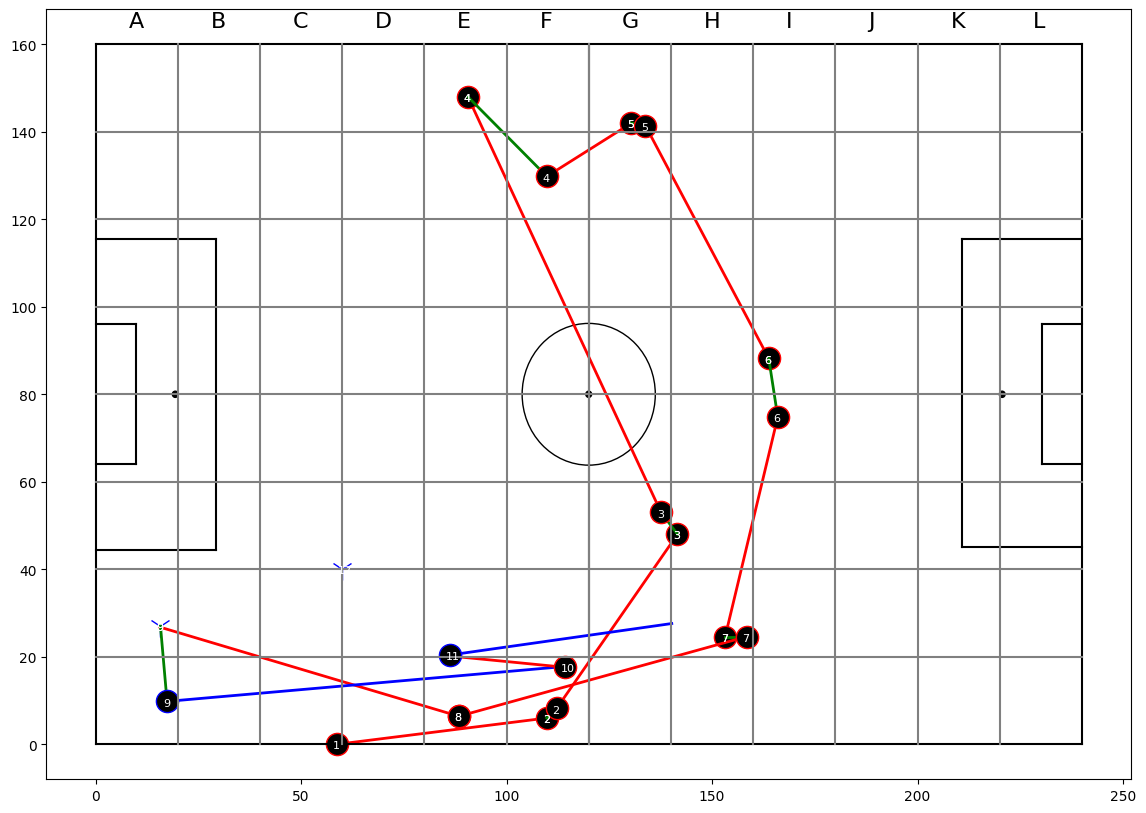

Team: Poland
1: Kamil Jóźwiak (Injury Stoppage) <00:11:58.725>
2: Grzegorz Krychowiak (Pass) <00:12:22.115>
3: Kamil Glik (Ball Receipt*) <00:12:22.721>
3: Kamil Glik (Pass) <00:12:24.308>
4: Jan Bednarek (Ball Receipt*) <00:12:25.780>
4: Jan Bednarek (Carry) <00:12:25.780>
4: Jan Bednarek (Pass) <00:12:29.131>
5: Bartosz Bereszyński (Ball Receipt*) <00:12:31.414>
5: Bartosz Bereszyński (Carry) <00:12:31.414>
5: Bartosz Bereszyński (Pass) <00:12:33.349>
6: Grzegorz Krychowiak (Ball Receipt*) <00:12:34.311>
6: Grzegorz Krychowiak (Carry) <00:12:34.311>
6: Grzegorz Krychowiak (Pass) <00:12:35.073>
7: Bartosz Bereszyński (Ball Receipt*) <00:12:36.443>
7: Bartosz Bereszyński (Carry) <00:12:36.443>
7: Bartosz Bereszyński (Pass) <00:12:37.601>
8: Kamil Glik (Ball Receipt*) <00:12:38.921>
8: Kamil Glik (Carry) <00:12:38.921>
8: Kamil Glik (Pass) <00:12:39.976>
9: Jan Bednarek (Ball Receipt*) <00:12:41.467>
9: Jan Bednarek (Carry) <00:12:41.467>
9: Jan Bednarek (Dispossessed) <00:12:42.702>
10

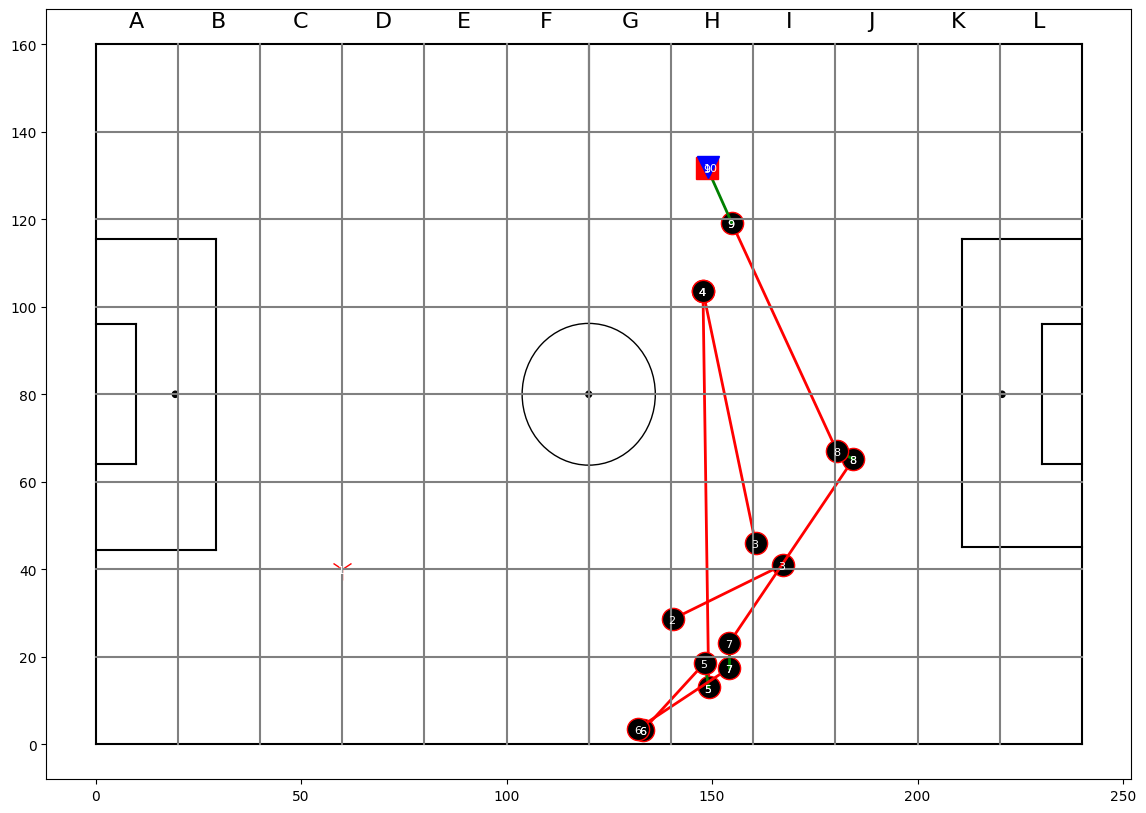

Team: Sweden
1: Mikael Lustig (Ball Recovery) <00:12:57.448>
1: Mikael Lustig (Carry) <00:12:57.448>
1: Mikael Lustig (Pass) <00:12:58.578>
2: Robin Quaison (Ball Receipt*) <00:13:00.169>
2: Robin Quaison (Pass) <00:13:00.169>
3: Alexander Isak (Ball Receipt*) <00:13:01.267>
3: Alexander Isak (Carry) <00:13:01.267>
3: Alexander Isak (Pass) <00:13:04.376>
4: Emil Peter Forsberg (Ball Receipt*) <00:13:05.583>
4: Emil Peter Forsberg (Carry) <00:13:05.583>
4: Emil Peter Forsberg (Pass) <00:13:09.874>
5: Mikael Lustig (Ball Receipt*) <00:13:12.929>
5: Mikael Lustig (Carry) <00:13:12.929>
5: Mikael Lustig (Pass) <00:13:12.969>
6: Jan Bednarek (Clearance) <00:13:13.759>
7: Mikael Lustig (Ball Recovery) <00:13:16.780>
7: Mikael Lustig (Carry) <00:13:16.780>
7: Mikael Lustig (Pass) <00:13:18.084>
8: Sebastian Larsson (Ball Receipt*) <00:13:19.281>
8: Sebastian Larsson (Carry) <00:13:19.281>
8: Sebastian Larsson (Pass) <00:13:20.174>
9: Piotr Zieliński (Interception) <00:13:21.476>
10: Mikael Lu

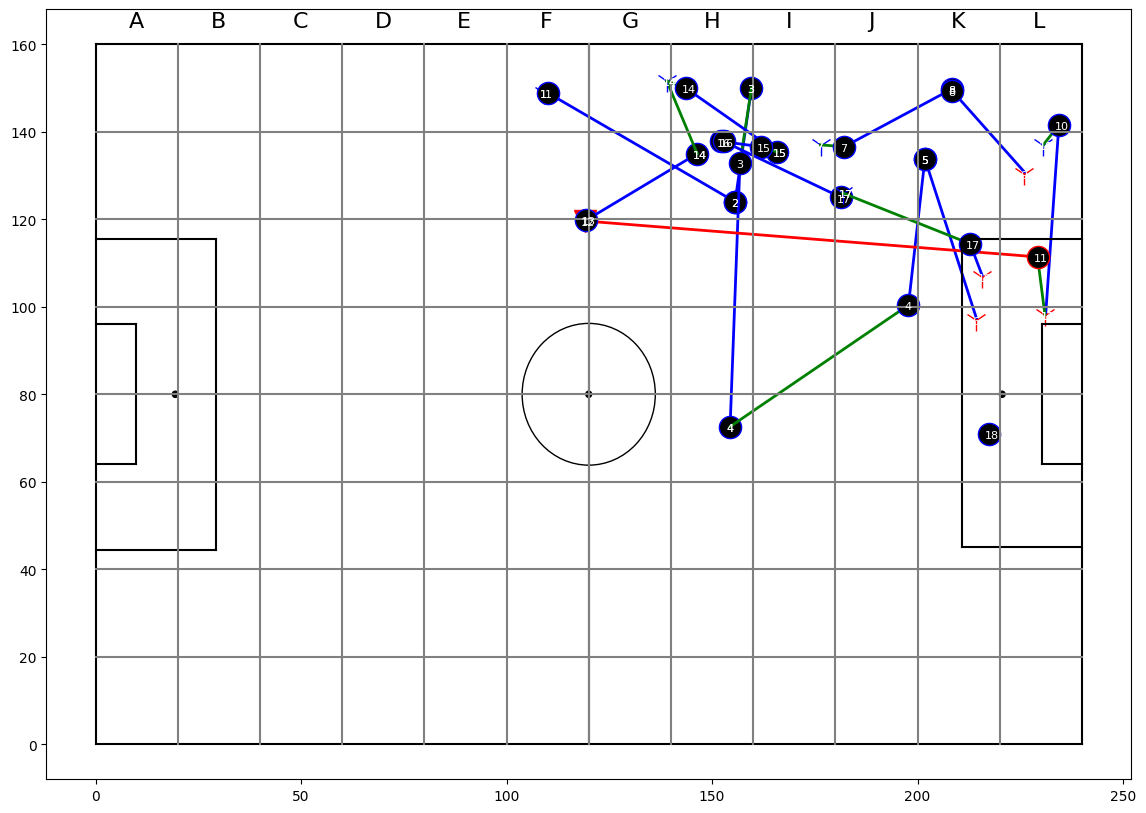

Team: Poland
1: Tymoteusz Puchacz (Pass) <00:22:49.711>
2: Piotr Zieliński (Ball Receipt*) <00:22:50.565>
2: Piotr Zieliński (Carry) <00:22:50.565>
2: Piotr Zieliński (Pass) <00:22:50.707>
3: Tymoteusz Puchacz (Ball Receipt*) <00:22:51.491>
3: Tymoteusz Puchacz (Carry) <00:22:51.491>
3: Tymoteusz Puchacz (Pass) <00:22:52.956>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:22:53.614>
4: Mateusz Andrzej Klich (Carry) <00:22:53.614>
4: Mateusz Andrzej Klich (Pass) <00:22:56.034>
5: Jan Bednarek (Ball Receipt*) <00:22:57.359>
5: Jan Bednarek (Carry) <00:22:57.359>
5: Jan Bednarek (Pass) <00:22:58.240>
6: Kamil Glik (Ball Receipt*) <00:23:00.521>
6: Kamil Glik (Carry) <00:23:00.521>
6: Kamil Glik (Pass) <00:23:00.891>
7: Bartosz Bereszyński (Ball Receipt*) <00:23:02.352>
7: Bartosz Bereszyński (Carry) <00:23:02.352>
7: Bartosz Bereszyński (Pass) <00:23:03.638>
8: Emil Peter Forsberg (Block) <00:23:03.886>
9: Kamil Jóźwiak (Pass) <00:23:06.288>
10: Karol Świderski (Ball Receipt*) <00:23:07.405

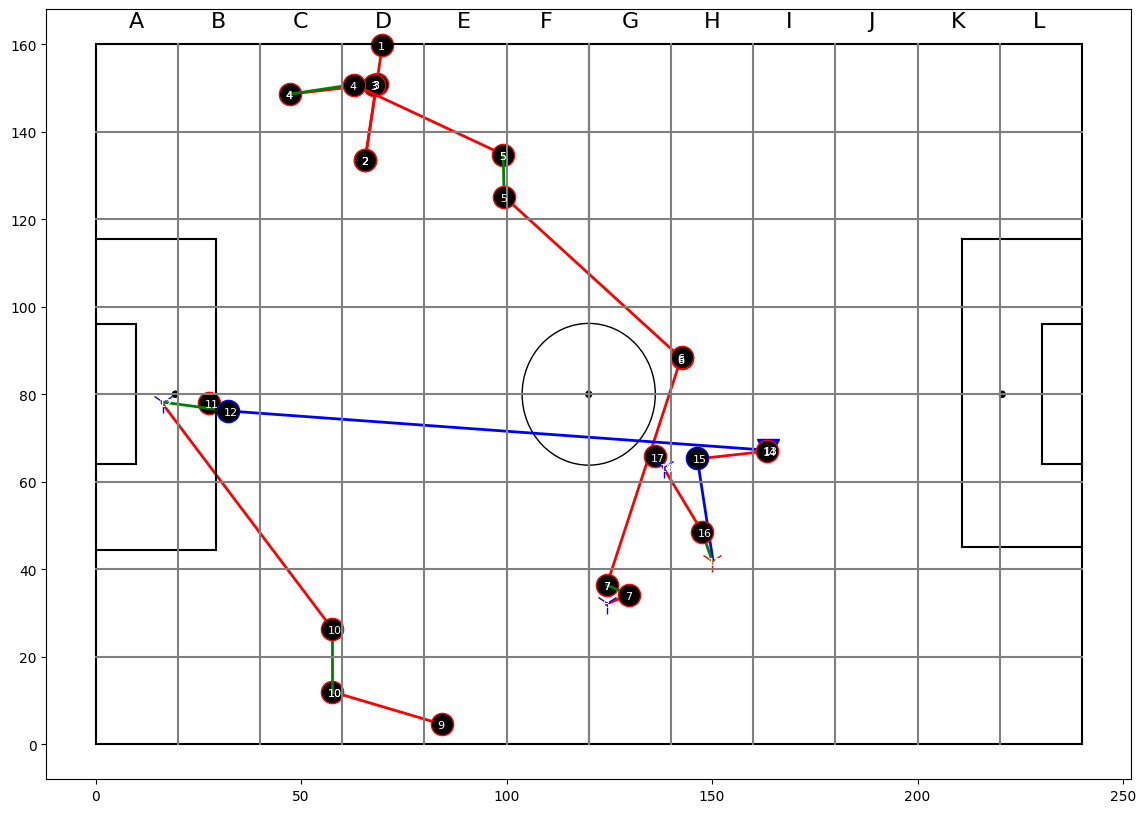

Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:23:41.851>
2: Sebastian Larsson (Ball Receipt*) <00:23:42.483>
2: Sebastian Larsson (Carry) <00:23:42.483>
2: Sebastian Larsson (Miscontrol) <00:23:42.553>
3: Victor Nilsson Lindelöf (Pass) <00:23:44.083>
4: Mikael Lustig (Ball Receipt*) <00:23:44.646>
4: Mikael Lustig (Pass) <00:23:44.646>
5: Robin Quaison (Ball Receipt*) <00:23:48.230>
5: Robin Quaison (Carry) <00:23:48.230>
6: Bartosz Bereszyński (Ball Recovery) <00:23:48.230>
7: Robin Quaison (Pass) <00:23:49.605>
8: Ludwig Augustinsson (Ball Receipt*) <00:23:51.198>
8: Ludwig Augustinsson (Carry) <00:23:51.198>
8: Ludwig Augustinsson (Pass) <00:23:53.333>
9: Marcus Andreas Danielsson (Ball Receipt*) <00:23:54.352>
9: Marcus Andreas Danielsson (Carry) <00:23:54.352>
9: Marcus Andreas Danielsson (Pass) <00:23:57.268>
10: Robin Olsen (Ball Receipt*) <00:24:00.111>
10: Robin Olsen (Carry) <00:24:00.111>
10: Robin Olsen (Pass) <00:24:02.167>
11: Alexander Isak (Ball Receipt*) <00:24:05

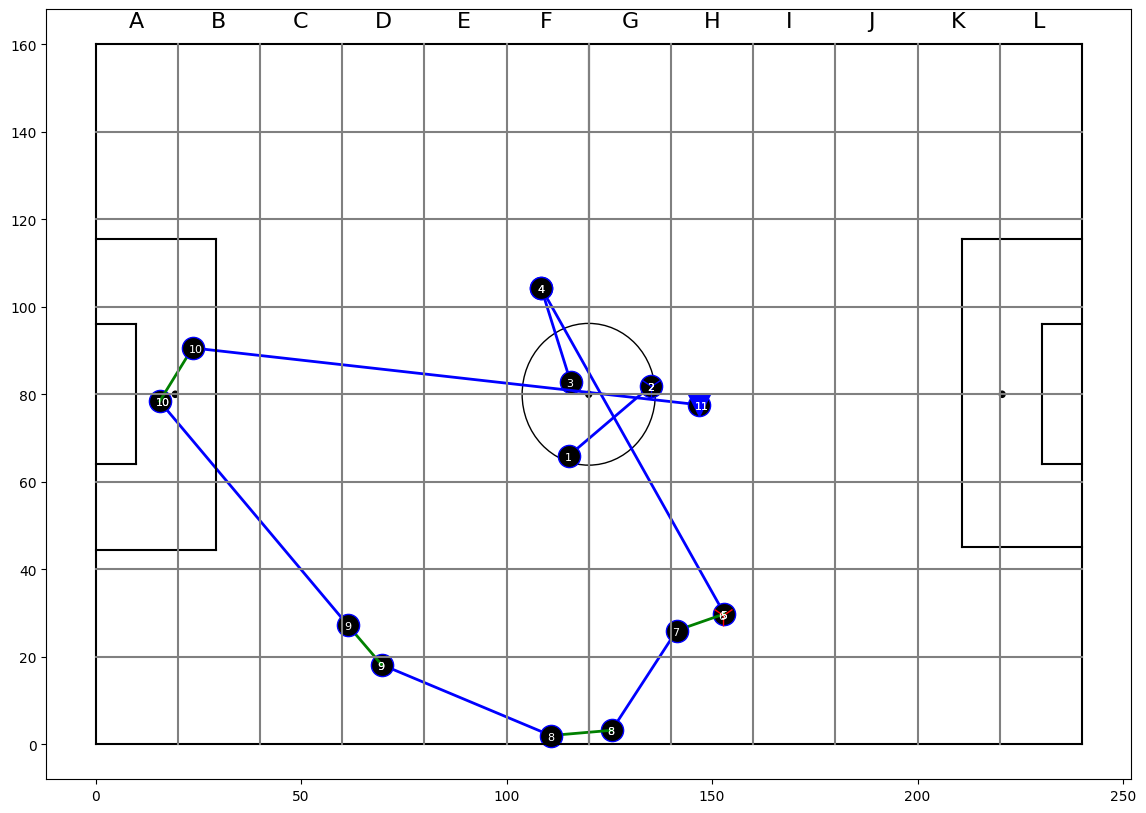

Team: Poland
1: Kamil Glik (Pass) <00:27:25.356>
2: Jan Bednarek (Ball Receipt*) <00:27:26.116>
2: Jan Bednarek (Pass) <00:27:30.202>
3: Bartosz Bereszyński (Ball Receipt*) <00:27:31.731>
3: Bartosz Bereszyński (Carry) <00:27:31.731>
3: Bartosz Bereszyński (Pass) <00:27:32.796>
4: Grzegorz Krychowiak (Ball Receipt*) <00:27:33.772>
4: Grzegorz Krychowiak (Carry) <00:27:33.772>
4: Grzegorz Krychowiak (Pass) <00:27:34.464>
5: Kamil Jóźwiak (Ball Receipt*) <00:27:35.442>
5: Kamil Jóźwiak (Carry) <00:27:35.442>
5: Kamil Jóźwiak (Pass) <00:27:39.105>
6: Piotr Zieliński (Ball Receipt*) <00:27:39.686>
6: Piotr Zieliński (Carry) <00:27:39.686>
6: Piotr Zieliński (Pass) <00:27:41.030>
7: Grzegorz Krychowiak (Ball Receipt*) <00:27:42.445>
7: Grzegorz Krychowiak (Carry) <00:27:42.445>
7: Grzegorz Krychowiak (Pass) <00:27:42.532>
8: Bartosz Bereszyński (Ball Receipt*) <00:27:43.875>
8: Bartosz Bereszyński (Carry) <00:27:43.875>
8: Bartosz Bereszyński (Pass) <00:27:45.166>
9: Jan Bednarek (Ball Rece

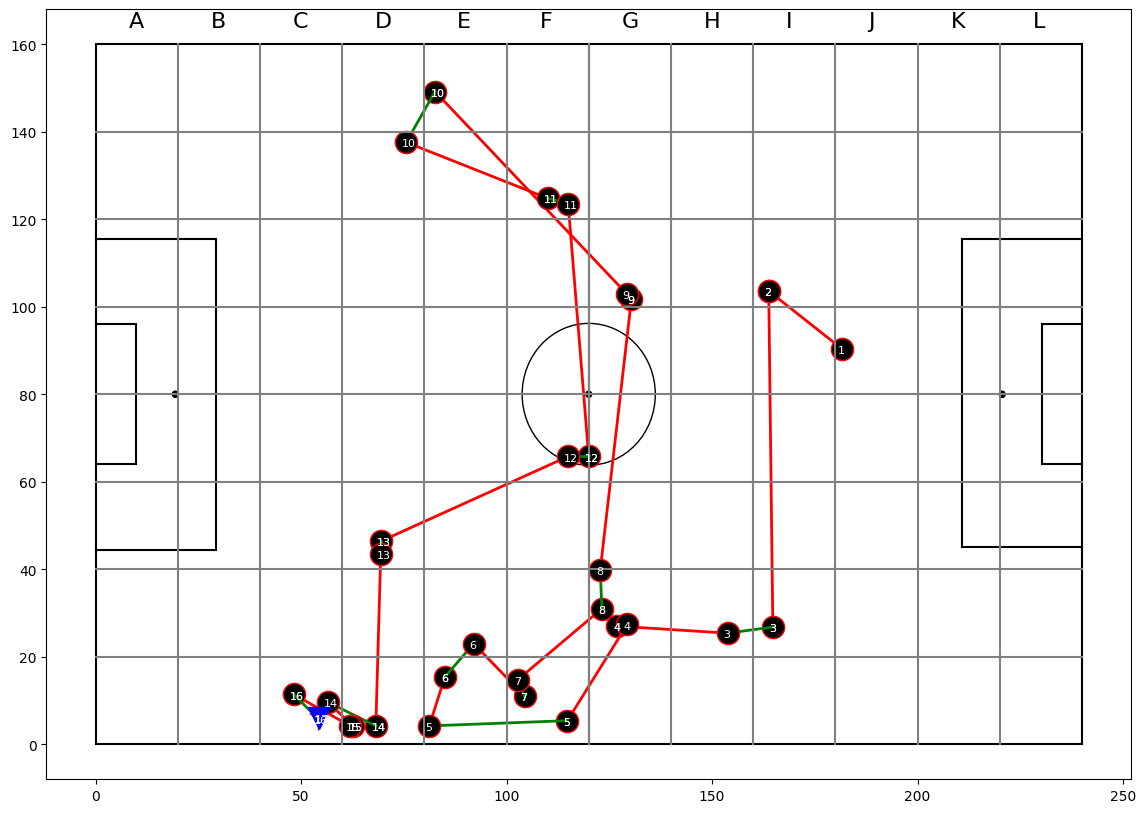

Team: Poland
1: Bartosz Bereszyński (Pass) <00:28:17.261>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:28:18.219>
2: Mateusz Andrzej Klich (Pass) <00:28:18.219>
3: Bartosz Bereszyński (Ball Receipt*) <00:28:19.195>
3: Bartosz Bereszyński (Carry) <00:28:19.195>
3: Bartosz Bereszyński (Pass) <00:28:20.284>
4: Kamil Jóźwiak (Ball Receipt*) <00:28:21.234>
4: Kamil Jóźwiak (Carry) <00:28:21.234>
4: Kamil Jóźwiak (Pass) <00:28:22.267>
5: Ludwig Augustinsson (Block) <00:28:22.420>
6: Grzegorz Krychowiak (Pass) <00:28:23.005>
7: Mateusz Andrzej Klich (Ball Receipt*) <00:28:23.105>
7: Mateusz Andrzej Klich (Carry) <00:28:23.105>
7: Mateusz Andrzej Klich (Pass) <00:28:25.155>
8: Marcus Andreas Danielsson (Clearance) <00:28:26.365>
9: Tymoteusz Puchacz (Ball Recovery) <00:28:28.595>
9: Tymoteusz Puchacz (Carry) <00:28:28.595>
9: Tymoteusz Puchacz (Pass) <00:28:29.652>
10: Karol Świderski (Ball Receipt*) <00:28:31.531>
11: Ludwig Augustinsson (Duel) <00:28:31.571>
12: Karol Świderski (Pass) <00:28

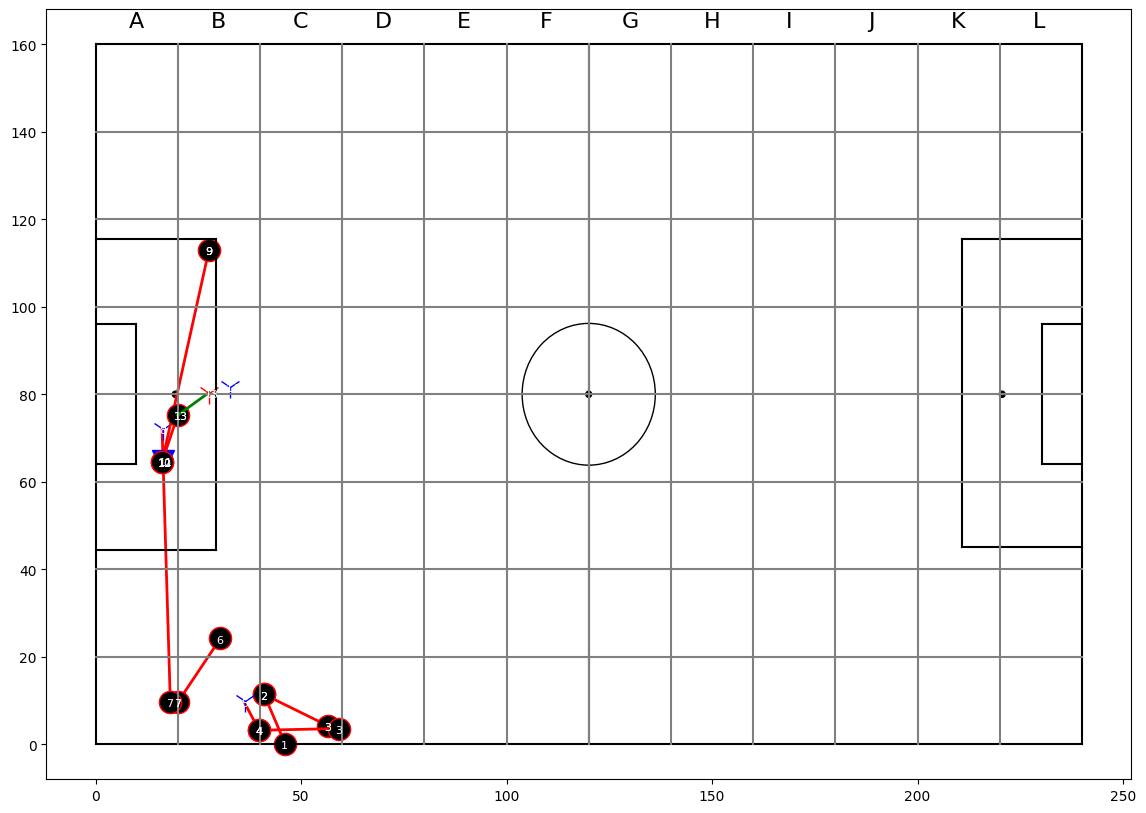

Team: Poland
1: Jan Bednarek (Pass) <00:29:19.274>
2: Wojciech Szczęsny (Ball Receipt*) <00:29:21.956>
2: Wojciech Szczęsny (Carry) <00:29:21.956>
2: Wojciech Szczęsny (Pass) <00:29:23.540>
3: Bartosz Bereszyński (Ball Receipt*) <00:29:24.879>
3: Bartosz Bereszyński (Carry) <00:29:24.879>
3: Bartosz Bereszyński (Pass) <00:29:26.206>
4: Kamil Jóźwiak (Ball Receipt*) <00:29:27.839>
4: Kamil Jóźwiak (Carry) <00:29:27.839>
4: Kamil Jóźwiak (Pass) <00:29:30.827>
5: Bartosz Bereszyński (Ball Receipt*) <00:29:32.045>
5: Bartosz Bereszyński (Carry) <00:29:32.045>
5: Bartosz Bereszyński (Pass) <00:29:34.205>
6: Piotr Zieliński (Ball Receipt*) <00:29:34.887>
6: Piotr Zieliński (Pass) <00:29:34.887>
7: Kamil Glik (Ball Receipt*) <00:29:36.576>
8: Robin Quaison (Ball Recovery) <00:29:36.576>
8: Robin Quaison (Carry) <00:29:36.576>
8: Robin Quaison (Pass) <00:29:37.787>
9: Mikael Lustig (Ball Receipt*) <00:29:39.877>
10: Tymoteusz Puchacz (Ball Recovery) <00:29:39.877>
10: Tymoteusz Puchacz (Carry)

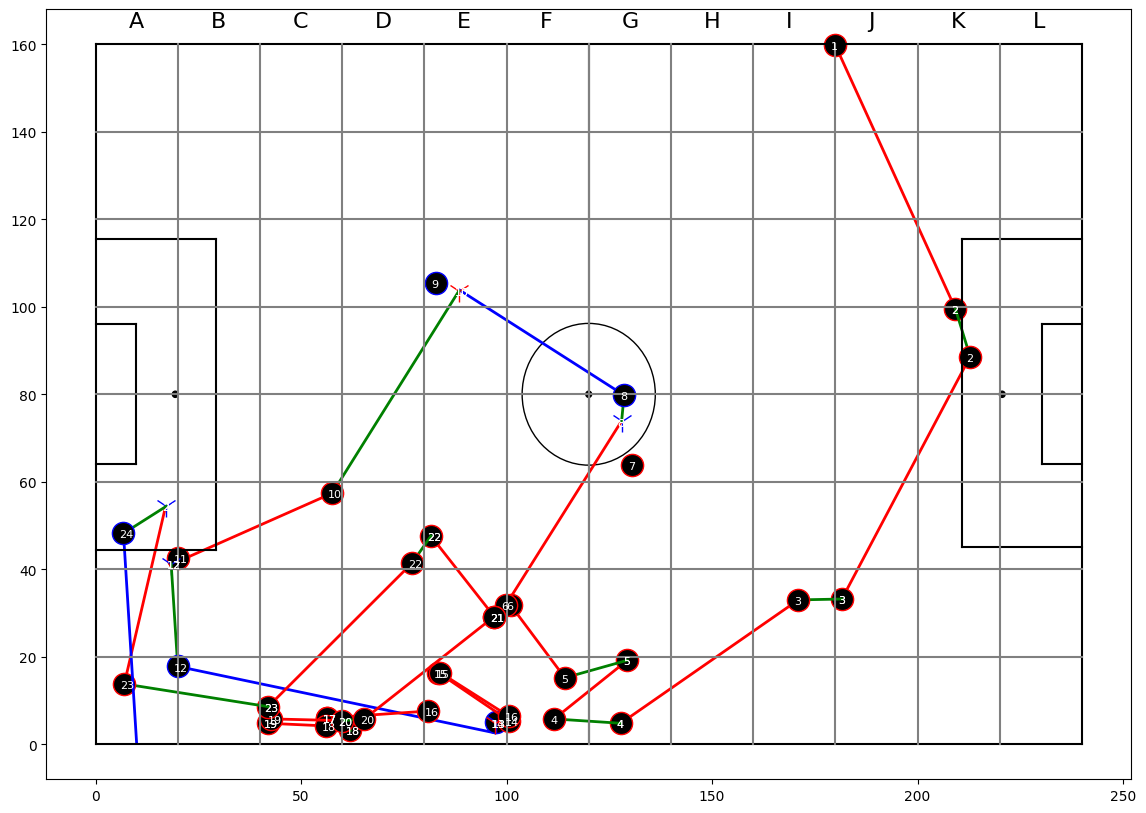

Team: Poland
1: Robert Lewandowski (Ball Recovery) <00:32:26.411>
1: Robert Lewandowski (Carry) <00:32:26.411>
1: Robert Lewandowski (Pass) <00:32:28.381>
2: Kamil Jóźwiak (Ball Receipt*) <00:32:28.478>
3: Emil Peter Forsberg (Block) <00:32:28.478>
3: Emil Peter Forsberg (Ball Recovery) <00:32:29.582>
4: Piotr Zieliński (Ball Recovery) <00:32:31.226>
4: Piotr Zieliński (Carry) <00:32:31.226>
4: Piotr Zieliński (Dispossessed) <00:32:32.967>
5: Albin Ekdal (Duel) <00:32:32.967>
6: Piotr Zieliński (Pass) <00:32:34.446>
7: Robert Lewandowski (Ball Receipt*) <00:32:35.239>
7: Robert Lewandowski (Carry) <00:32:35.239>
7: Robert Lewandowski (Pass) <00:32:36.960>
8: Ludwig Augustinsson (Block) <00:32:37.064>
9: Sebastian Larsson (Foul Committed) <00:32:41.223>
10: Kamil Jóźwiak (Foul Won) <00:32:41.223>
11: Piotr Zieliński (Pass) <00:33:05.326>
12: Grzegorz Krychowiak (Ball Receipt*) <00:33:07.313>
13: Albin Ekdal (Clearance) <00:33:07.313>
14: Kamil Jóźwiak (Ball Recovery) <00:33:09.691>
14: 

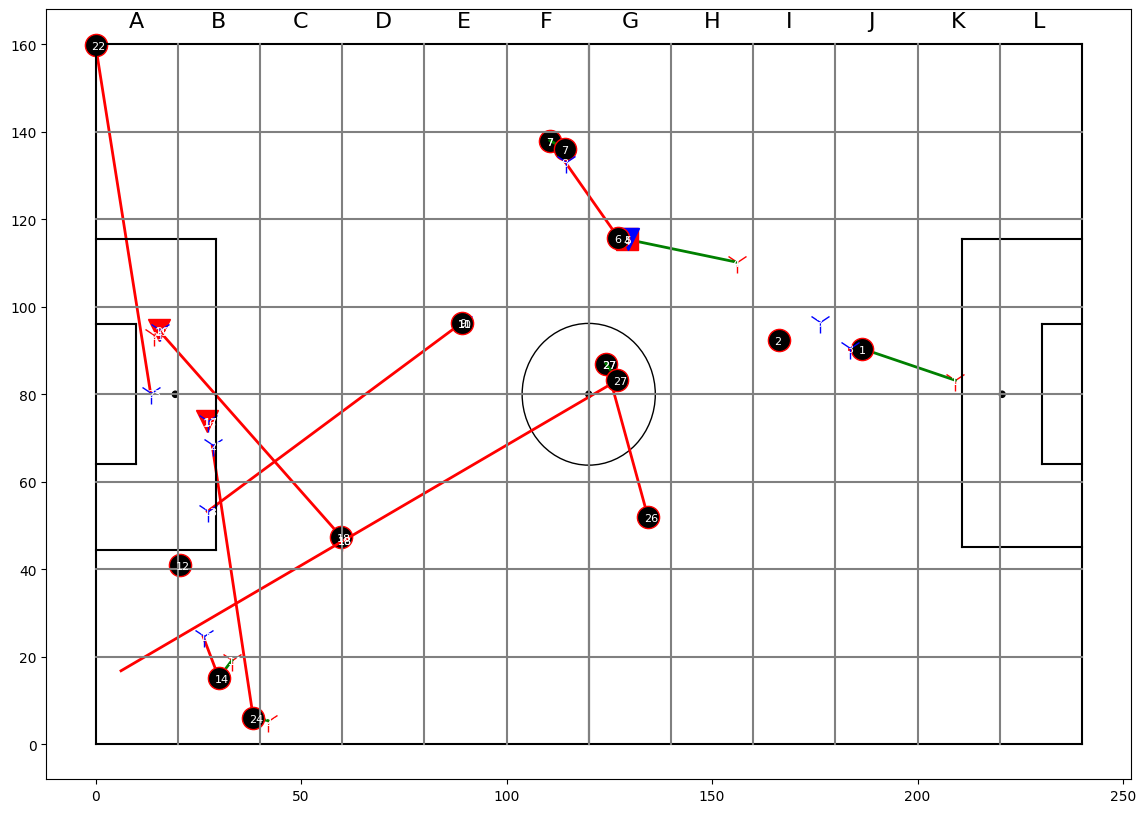

Team: Poland
1: Albin Ekdal (Foul Committed) <00:36:02.431>
2: Piotr Zieliński (Foul Won) <00:36:02.431>
3: Bartosz Bereszyński (Pass) <00:36:21.505>
4: Kamil Glik (Ball Receipt*) <00:36:22.528>
4: Kamil Glik (Pass) <00:36:23.136>
5: Jan Bednarek (Ball Receipt*) <00:36:24.245>
5: Jan Bednarek (Carry) <00:36:24.245>
5: Jan Bednarek (Pass) <00:36:25.360>
6: Tymoteusz Puchacz (Ball Receipt*) <00:36:26.646>
6: Tymoteusz Puchacz (Carry) <00:36:26.646>
6: Tymoteusz Puchacz (Dribble) <00:36:29.516>
7: Sebastian Larsson (Duel) <00:36:29.516>
7: Sebastian Larsson (Carry) <00:36:29.516>
7: Sebastian Larsson (Pass) <00:36:30.642>
8: Alexander Isak (Ball Receipt*) <00:36:32.175>
9: Jan Bednarek (Ball Recovery) <00:36:32.175>
9: Jan Bednarek (Carry) <00:36:32.175>
9: Jan Bednarek (Pass) <00:36:34.903>
10: Wojciech Szczęsny (Ball Receipt*) <00:36:38.539>
10: Wojciech Szczęsny (Pass) <00:36:38.539>
11: Mikael Lustig (Ball Recovery) <00:36:42.182>
11: Mikael Lustig (Carry) <00:36:42.182>
11: Mikael Lu

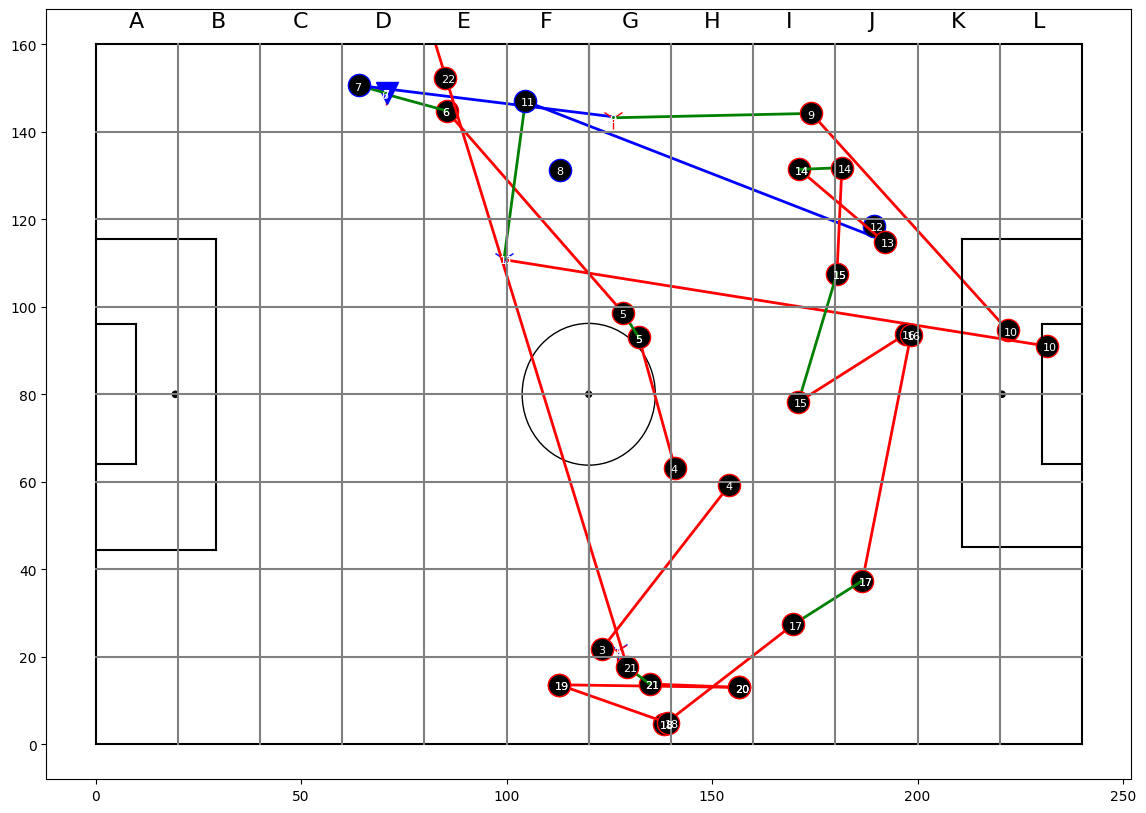

Team: Poland
1: Piotr Zieliński (Pass) <00:39:30.412>
2: Robert Lewandowski (Duel) <00:39:31.984>
3: Victor Nilsson Lindelöf (Clearance) <00:39:31.984>
4: Robert Lewandowski (Block) <00:39:32.031>
5: Kristoffer Olsson (Pass) <00:39:33.483>
6: Mikael Lustig (Ball Receipt*) <00:39:38.106>
6: Mikael Lustig (Carry) <00:39:38.106>
6: Mikael Lustig (Pass) <00:39:40.061>
7: Emil Peter Forsberg (Ball Receipt*) <00:39:43.774>
8: Mateusz Andrzej Klich (Pass) <00:39:43.774>
9: Bartosz Bereszyński (Ball Receipt*) <00:39:45.333>
9: Bartosz Bereszyński (Carry) <00:39:45.333>
9: Bartosz Bereszyński (Pass) <00:39:48.252>
10: Grzegorz Krychowiak (Ball Receipt*) <00:39:49.609>
10: Grzegorz Krychowiak (Carry) <00:39:49.609>
10: Grzegorz Krychowiak (Pass) <00:39:51.611>
11: Marcus Andreas Danielsson (Clearance) <00:39:53.007>
12: Mikael Lustig (Clearance) <00:39:54.390>
13: Alexander Isak (Foul Committed) <00:39:58.079>
14: Jan Bednarek (Foul Won) <00:39:58.079>
15: Mateusz Andrzej Klich (Pass) <00:40:08.

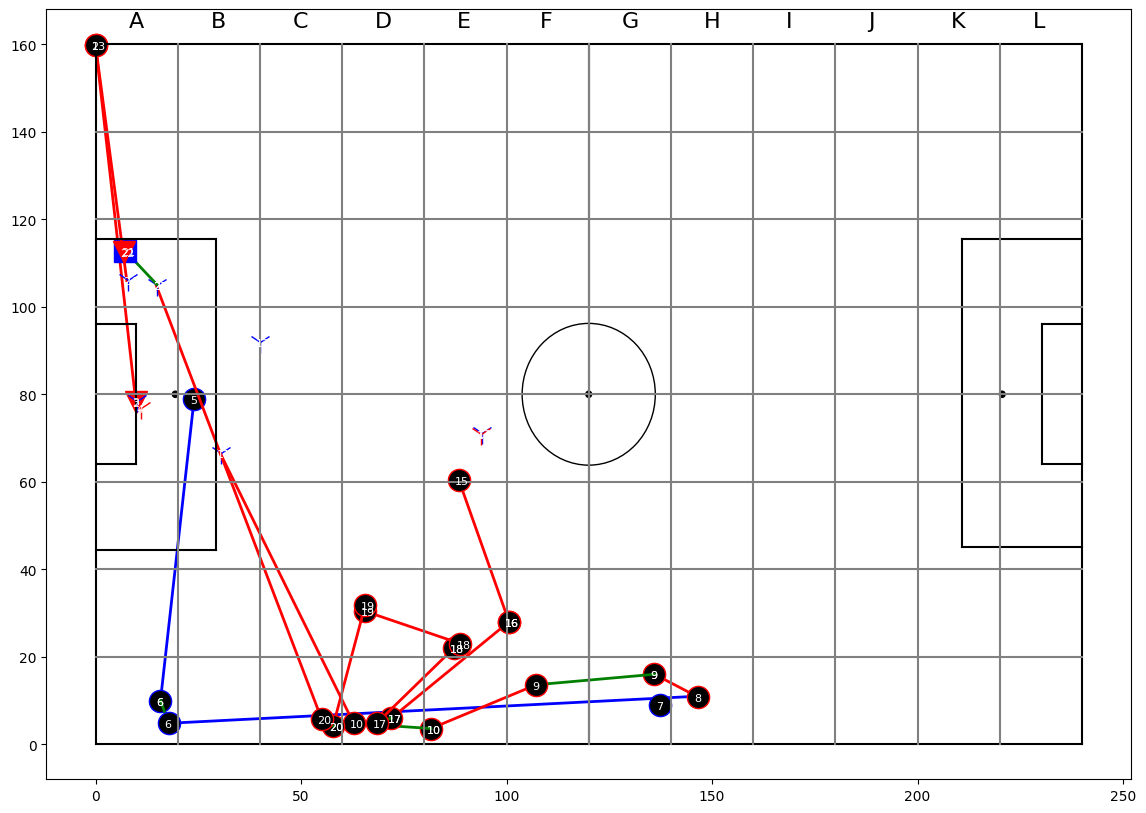

Team: Poland
1: Piotr Zieliński (Pass) <00:41:08.497>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:41:08.821>
2: Mateusz Andrzej Klich (Carry) <00:41:08.821>
2: Mateusz Andrzej Klich (Pass) <00:41:10.517>
3: Grzegorz Krychowiak (Duel) <00:41:12.368>
4: Victor Nilsson Lindelöf (Clearance) <00:41:12.368>
5: Bartosz Bereszyński (Ball Recovery) <00:41:14.391>
5: Bartosz Bereszyński (Shot) <00:41:14.474>
6: Kamil Glik (Ball Recovery) <00:41:15.604>
6: Kamil Glik (Carry) <00:41:15.604>
6: Kamil Glik (Pass) <00:41:16.414>
7: Piotr Zieliński (Ball Receipt*) <00:41:17.218>
7: Piotr Zieliński (Shot) <00:41:17.235>
8: Alexander Isak (Block) <00:41:17.471>
9: Ludwig Augustinsson (Clearance) <00:41:18.705>
10: Mateusz Andrzej Klich (Pass) <00:41:24.283>
11: Wojciech Szczęsny (Ball Receipt*) <00:41:27.034>
11: Wojciech Szczęsny (Carry) <00:41:27.034>
11: Wojciech Szczęsny (Pass) <00:41:29.158>
12: Robert Lewandowski (Ball Receipt*) <00:41:32.071>
12: Robert Lewandowski (Duel) <00:41:32.071>
13: Marc

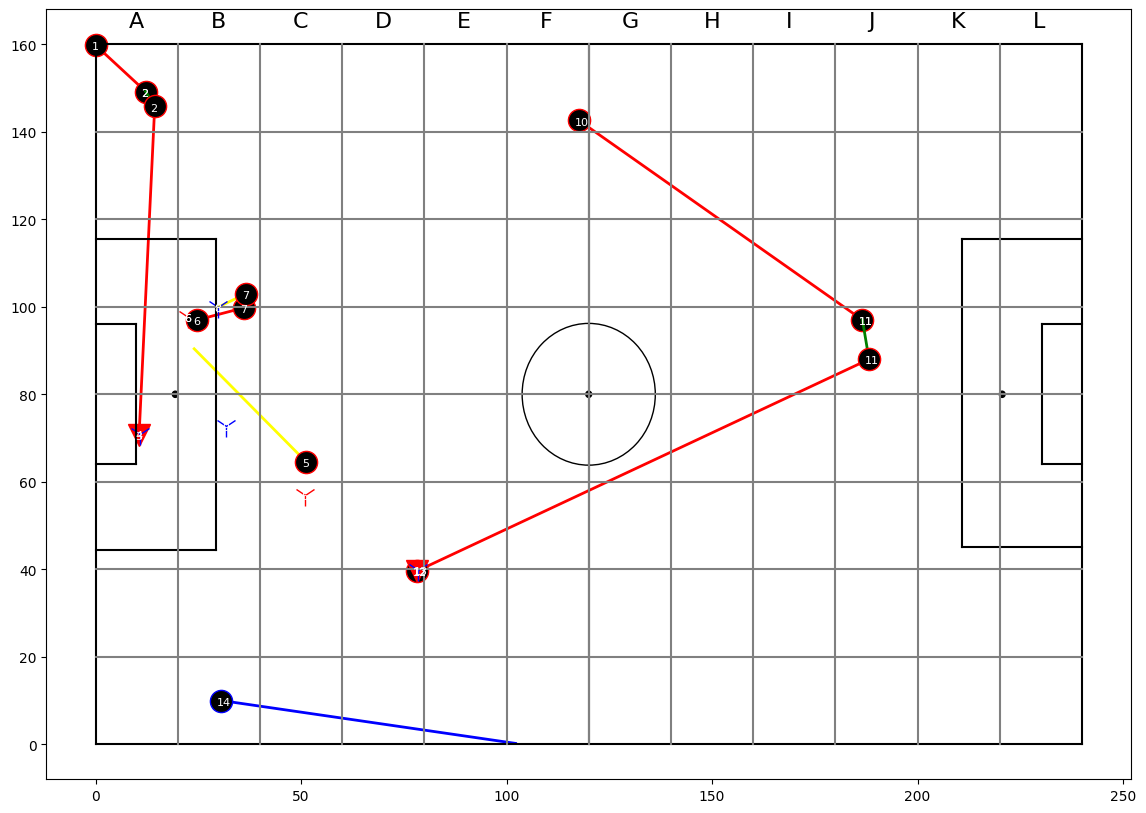

Team: Poland
1: Bartosz Bereszyński (Pass) <00:41:41.573>
2: Grzegorz Krychowiak (Ball Receipt*) <00:41:42.616>
2: Grzegorz Krychowiak (Carry) <00:41:42.616>
2: Grzegorz Krychowiak (Pass) <00:41:46.277>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:41:47.093>
3: Mateusz Andrzej Klich (Carry) <00:41:47.093>
3: Mateusz Andrzej Klich (Pass) <00:41:48.210>
4: Tymoteusz Puchacz (Ball Receipt*) <00:41:49.776>
4: Tymoteusz Puchacz (Carry) <00:41:49.776>
4: Tymoteusz Puchacz (Pass) <00:41:52.234>
5: Mikael Lustig (Clearance) <00:41:52.930>
6: Emil Peter Forsberg (Pass) <00:41:54.377>
7: Robin Quaison (Ball Receipt*) <00:41:55.647>
7: Robin Quaison (Carry) <00:41:55.647>
7: Robin Quaison (Dribble) <00:41:56.240>
8: Bartosz Bereszyński (Duel) <00:41:56.240>
9: Jan Bednarek (Pass) <00:41:58.381>
10: Kamil Jóźwiak (Ball Receipt*) <00:42:00.188>
10: Kamil Jóźwiak (Carry) <00:42:00.188>
10: Kamil Jóźwiak (Pass) <00:42:02.464>
11: Marcus Andreas Danielsson (Clearance) <00:42:03.760>


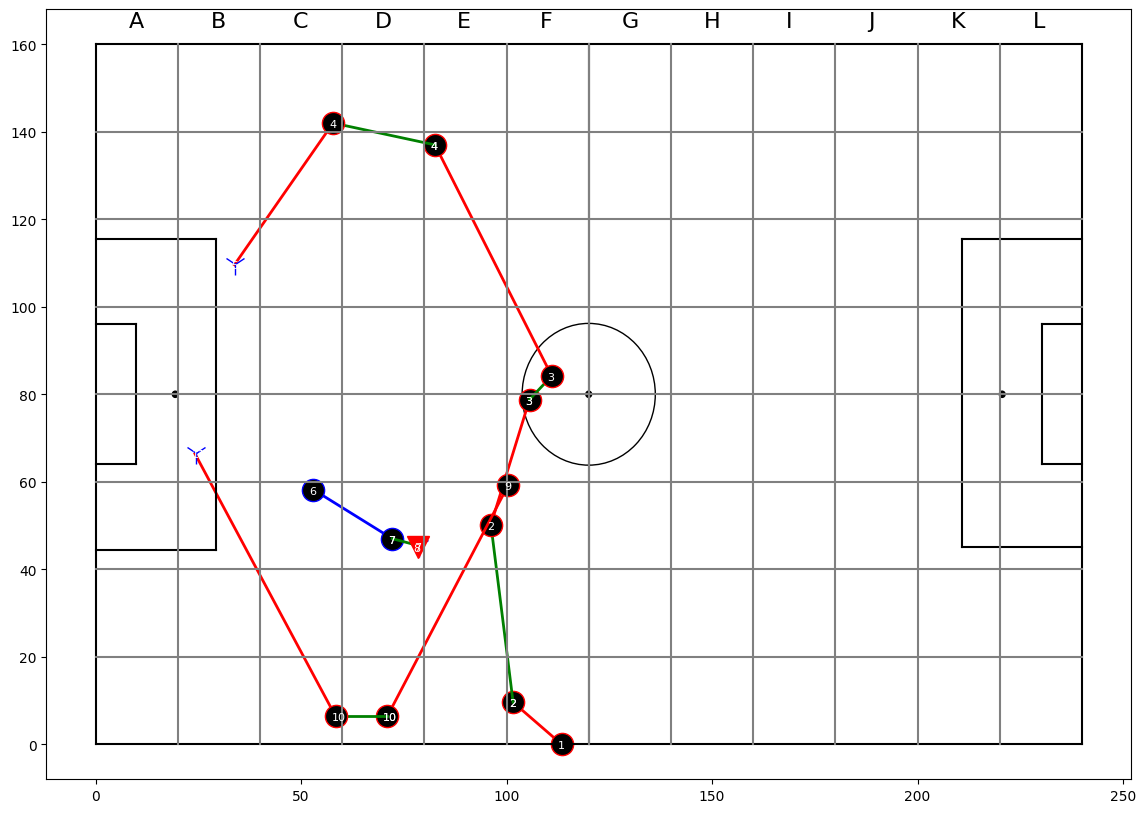

Team: Poland
1: Tymoteusz Puchacz (Pass) <00:43:48.629>
2: Grzegorz Krychowiak (Ball Receipt*) <00:43:50.233>
2: Grzegorz Krychowiak (Carry) <00:43:50.233>
2: Grzegorz Krychowiak (Pass) <00:43:50.238>
3: Piotr Zieliński (Ball Receipt*) <00:43:51.068>
3: Piotr Zieliński (Carry) <00:43:51.068>
3: Piotr Zieliński (Pass) <00:43:53.479>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:43:55.497>
4: Mateusz Andrzej Klich (Carry) <00:43:55.497>
4: Mateusz Andrzej Klich (Pass) <00:43:57.550>
5: Emil Peter Forsberg (Clearance) <00:44:00.282>
6: Bartosz Bereszyński (Ball Recovery) <00:44:03.419>
6: Bartosz Bereszyński (Carry) <00:44:03.419>
6: Bartosz Bereszyński (Pass) <00:44:05.825>
7: Mateusz Andrzej Klich (Ball Receipt*) <00:44:06.801>
7: Mateusz Andrzej Klich (Carry) <00:44:06.801>
7: Mateusz Andrzej Klich (Pass) <00:44:08.293>
8: Bartosz Bereszyński (Ball Receipt*) <00:44:09.300>
8: Bartosz Bereszyński (Carry) <00:44:09.300>
8: Bartosz Bereszyński (Pass) <00:44:10.401>
9: Kamil Jóźwiak (Ball R

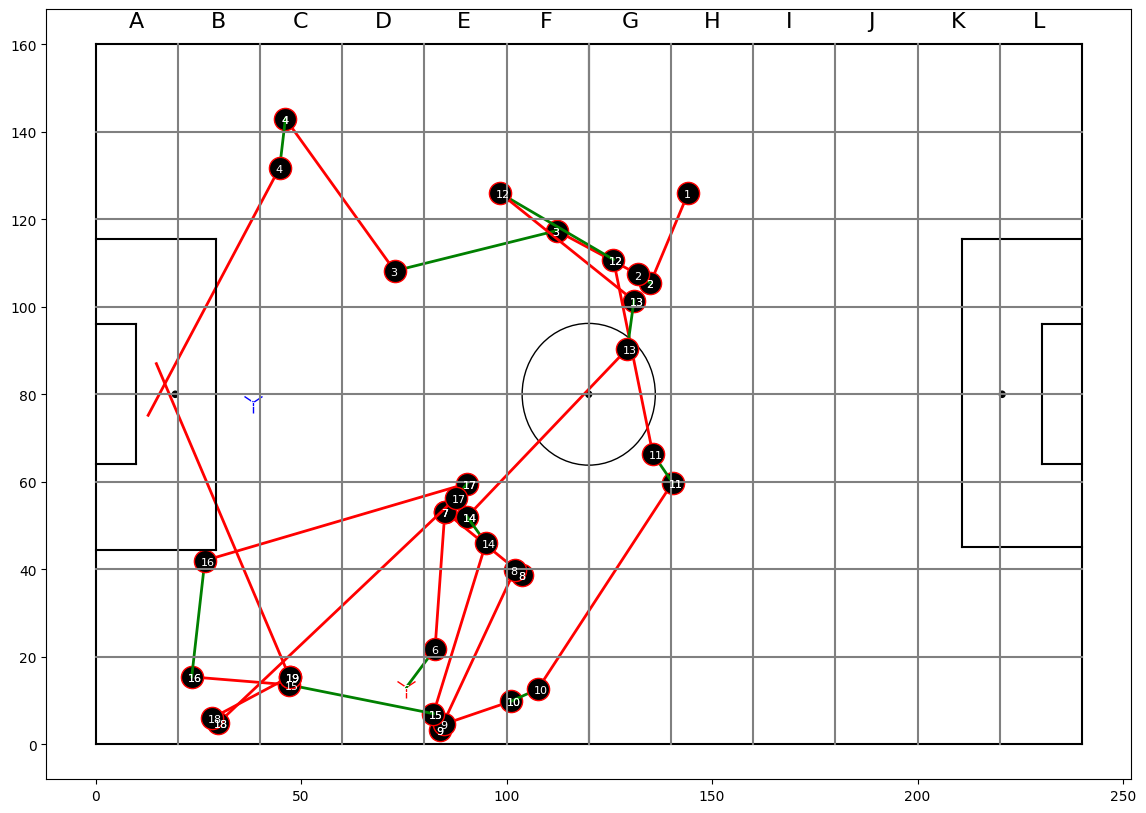

Team: Poland
1: Bartosz Bereszyński (Pass) <00:45:19.850>
2: Kamil Jóźwiak (Ball Receipt*) <00:45:20.968>
2: Kamil Jóźwiak (Carry) <00:45:20.968>
2: Kamil Jóźwiak (Pass) <00:45:26.995>
3: Piotr Zieliński (Ball Receipt*) <00:45:28.009>
3: Piotr Zieliński (Pass) <00:45:28.009>
4: Robert Lewandowski (Ball Receipt*) <00:45:28.625>
4: Robert Lewandowski (Pass) <00:45:28.625>
5: Piotr Zieliński (Ball Receipt*) <00:45:29.849>
5: Piotr Zieliński (Carry) <00:45:29.849>
5: Piotr Zieliński (Shot) <00:45:31.002>
5: Piotr Zieliński (Pass) <00:45:50.895>
6: Robert Lewandowski (Duel) <00:45:52.552>
7: Victor Nilsson Lindelöf (Clearance) <00:45:52.552>
8: Kristoffer Olsson (Clearance) <00:45:54.154>
9: Wojciech Szczęsny (Pass) <00:45:58.979>
10: Bartosz Bereszyński (Ball Receipt*) <00:46:00.628>
10: Bartosz Bereszyński (Carry) <00:46:00.628>
10: Bartosz Bereszyński (Pass) <00:46:02.652>
11: Karol Świderski (Ball Receipt*) <00:46:05.533>
12: Mikael Lustig (Duel) <00:46:05.533>
13: Karol Świderski (Pass

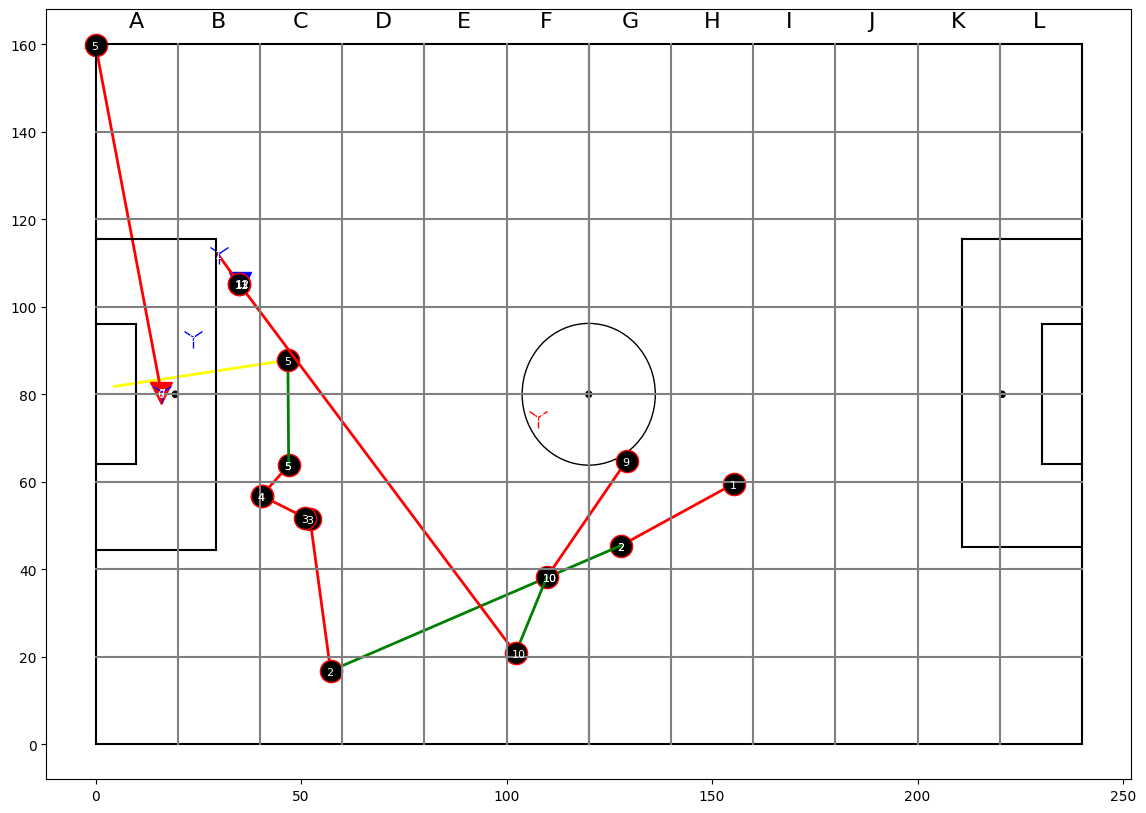

Team: Poland
1: Przemysław Frankowski (Pass) <00:00:23.609>
2: Jan Bednarek (Ball Receipt*) <00:00:25.099>
2: Jan Bednarek (Carry) <00:00:25.099>
2: Jan Bednarek (Pass) <00:00:26.725>
3: Bartosz Bereszyński (Ball Receipt*) <00:00:29.433>
3: Bartosz Bereszyński (Carry) <00:00:29.433>
3: Bartosz Bereszyński (Pass) <00:00:30.529>
4: Kamil Jóźwiak (Ball Receipt*) <00:00:32.272>
4: Kamil Jóźwiak (Carry) <00:00:32.272>
4: Kamil Jóźwiak (Pass) <00:00:35.382>
5: Kamil Glik (Ball Receipt*) <00:00:37.105>
5: Kamil Glik (Carry) <00:00:37.105>
5: Kamil Glik (Pass) <00:00:37.929>
6: Jan Bednarek (Ball Receipt*) <00:00:39.381>
6: Jan Bednarek (Carry) <00:00:39.381>
6: Jan Bednarek (Pass) <00:00:41.503>
7: Kamil Glik (Ball Receipt*) <00:00:43.930>
7: Kamil Glik (Carry) <00:00:43.930>
7: Kamil Glik (Pass) <00:00:46.187>
8: Bartosz Bereszyński (Ball Receipt*) <00:00:47.454>
8: Bartosz Bereszyński (Carry) <00:00:47.454>
8: Bartosz Bereszyński (Pass) <00:00:49.277>


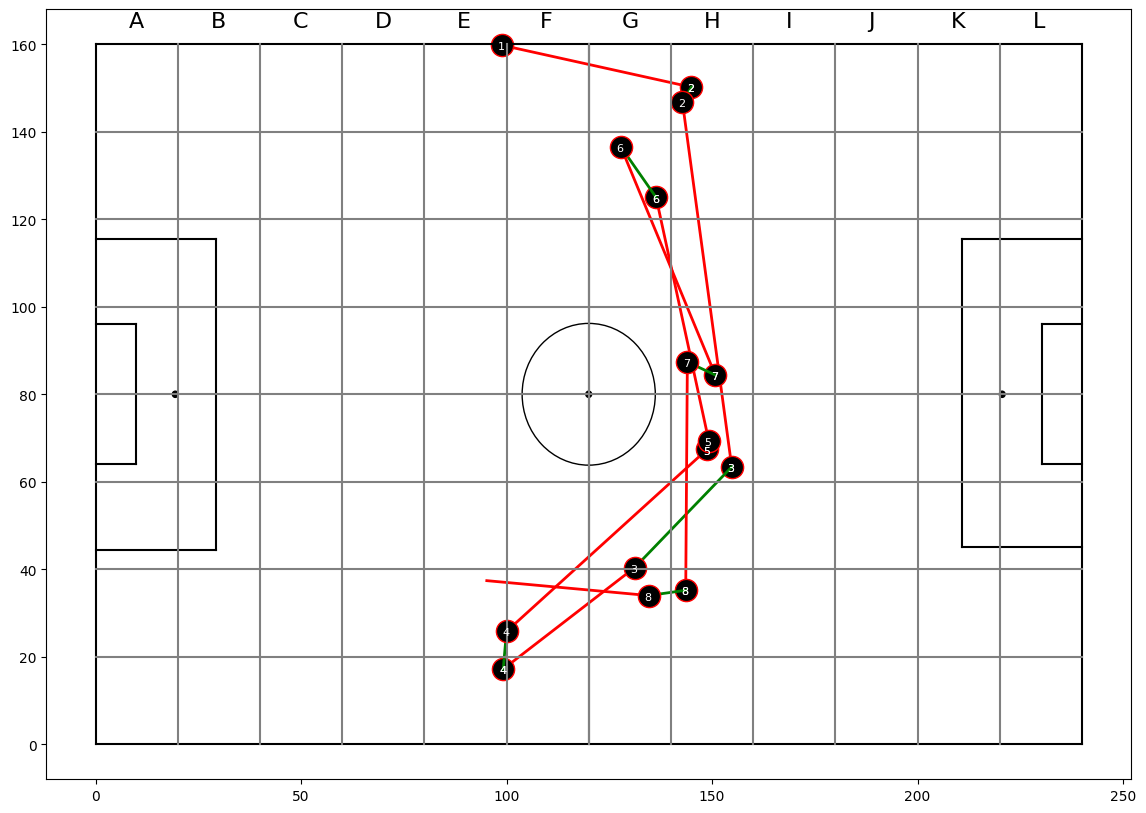

Team: Poland
1: Jan Bednarek (Pass) <00:01:17.751>
2: Kamil Glik (Ball Receipt*) <00:01:19.374>
2: Kamil Glik (Carry) <00:01:19.374>
2: Kamil Glik (Pass) <00:01:20.762>
3: Bartosz Bereszyński (Ball Receipt*) <00:01:22.165>
3: Bartosz Bereszyński (Carry) <00:01:22.165>
3: Bartosz Bereszyński (Pass) <00:01:24.218>
4: Jan Bednarek (Ball Receipt*) <00:01:25.867>
4: Jan Bednarek (Carry) <00:01:25.867>
4: Jan Bednarek (Pass) <00:01:26.927>
5: Grzegorz Krychowiak (Ball Receipt*) <00:01:28.213>
5: Grzegorz Krychowiak (Carry) <00:01:28.213>
5: Grzegorz Krychowiak (Pass) <00:01:28.517>
6: Jan Bednarek (Ball Receipt*) <00:01:29.690>
6: Jan Bednarek (Carry) <00:01:29.690>
6: Jan Bednarek (Pass) <00:01:34.856>
7: Kamil Glik (Ball Receipt*) <00:01:36.138>
7: Kamil Glik (Carry) <00:01:36.138>
7: Kamil Glik (Pass) <00:01:37.760>
8: Bartosz Bereszyński (Ball Receipt*) <00:01:38.984>
8: Bartosz Bereszyński (Carry) <00:01:38.984>
8: Bartosz Bereszyński (Pass) <00:01:39.761>
9: Kamil Jóźwiak (Ball Receipt

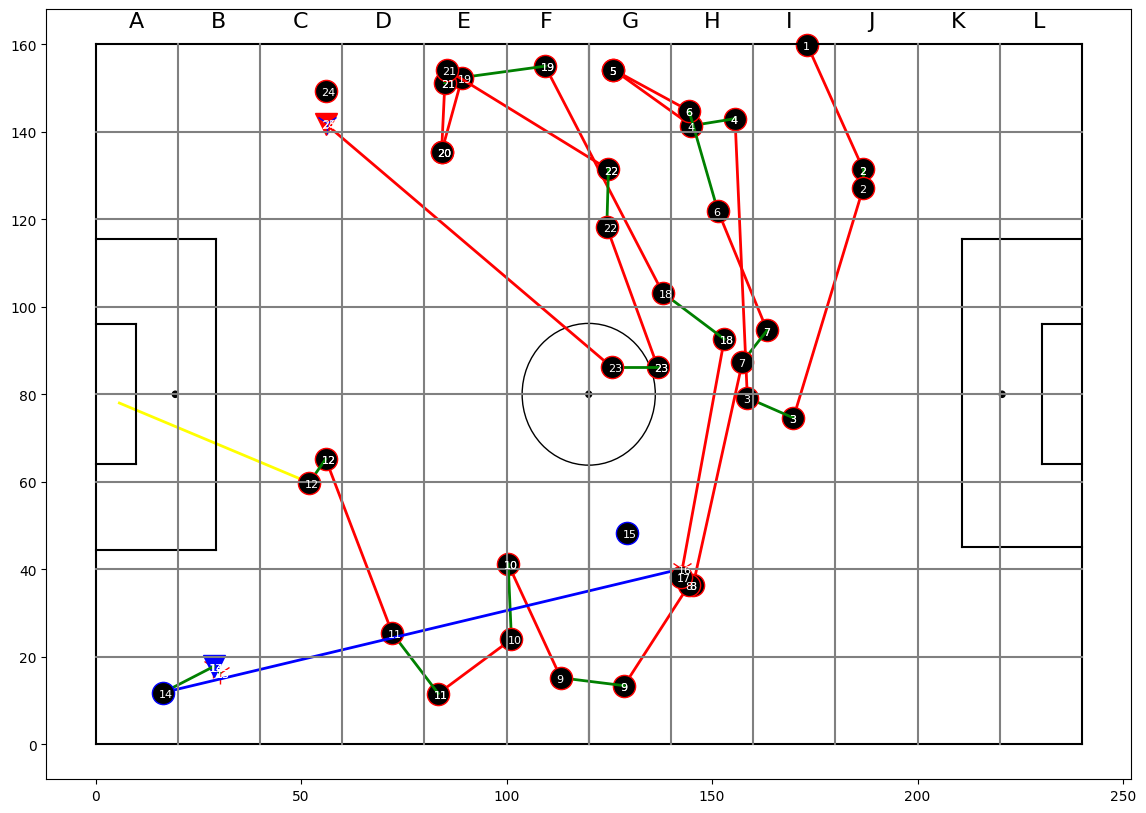

Team: Poland
1: Grzegorz Krychowiak (Pass) <00:02:37.987>
2: Przemysław Frankowski (Ball Receipt*) <00:02:38.650>
2: Przemysław Frankowski (Pass) <00:02:38.996>
3: Robert Lewandowski (Ball Receipt*) <00:02:40.244>
3: Robert Lewandowski (Pass) <00:02:40.794>
4: Jan Bednarek (Ball Receipt*) <00:02:42.395>
4: Jan Bednarek (Carry) <00:02:42.395>
4: Jan Bednarek (Pass) <00:02:43.874>
5: Kamil Glik (Ball Receipt*) <00:02:45.374>
5: Kamil Glik (Carry) <00:02:45.374>
5: Kamil Glik (Pass) <00:02:46.560>
6: Bartosz Bereszyński (Ball Receipt*) <00:02:47.847>
6: Bartosz Bereszyński (Carry) <00:02:47.847>
6: Bartosz Bereszyński (Pass) <00:02:49.086>
7: Kamil Jóźwiak (Ball Receipt*) <00:02:50.578>
7: Kamil Jóźwiak (Carry) <00:02:50.578>
7: Kamil Jóźwiak (Pass) <00:02:53.129>
8: Piotr Zieliński (Ball Receipt*) <00:02:54.189>
8: Piotr Zieliński (Pass) <00:02:54.189>
9: Kamil Jóźwiak (Ball Receipt*) <00:02:55.258>
9: Kamil Jóźwiak (Carry) <00:02:55.258>
9: Kamil Jóźwiak (Pass) <00:02:56.157>
10: Mateus

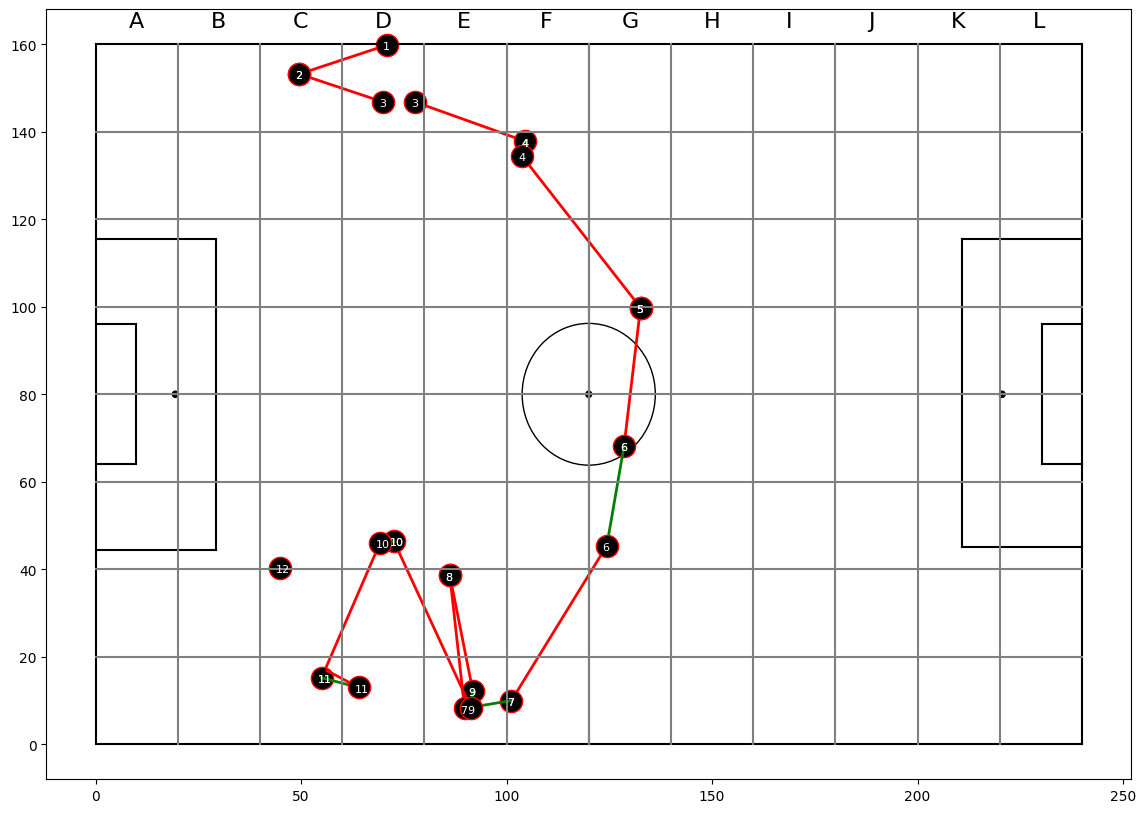

Team: Sweden
1: Robin Olsen (Ball Recovery) <00:10:26.507>
1: Robin Olsen (Carry) <00:10:26.507>
1: Robin Olsen (Pass) <00:10:29.115>
2: Marcus Andreas Danielsson (Ball Receipt*) <00:10:30.474>
2: Marcus Andreas Danielsson (Carry) <00:10:30.474>
2: Marcus Andreas Danielsson (Pass) <00:10:34.821>
3: Dejan Kulusevski (Ball Receipt*) <00:10:36.337>
4: Grzegorz Krychowiak (Interception) <00:10:36.337>
5: Kristoffer Olsson (Ball Recovery) <00:10:38.148>
5: Kristoffer Olsson (Carry) <00:10:38.148>
5: Kristoffer Olsson (Shot) <00:10:43.060>
6: Jan Bednarek (Block) <00:10:43.349>
7: Piotr Zieliński (Ball Recovery) <00:10:45.331>
7: Piotr Zieliński (Carry) <00:10:45.331>
7: Piotr Zieliński (Pass) <00:10:46.779>
8: Kamil Jóźwiak (Ball Receipt*) <00:10:49.706>
8: Kamil Jóźwiak (Carry) <00:10:49.706>
8: Kamil Jóźwiak (Dispossessed) <00:10:49.759>
9: Albin Ekdal (Duel) <00:10:49.759>
9: Albin Ekdal (Carry) <00:10:49.759>
9: Albin Ekdal (Pass) <00:10:54.025>
10: Emil Peter Forsberg (Ball Receipt*) <

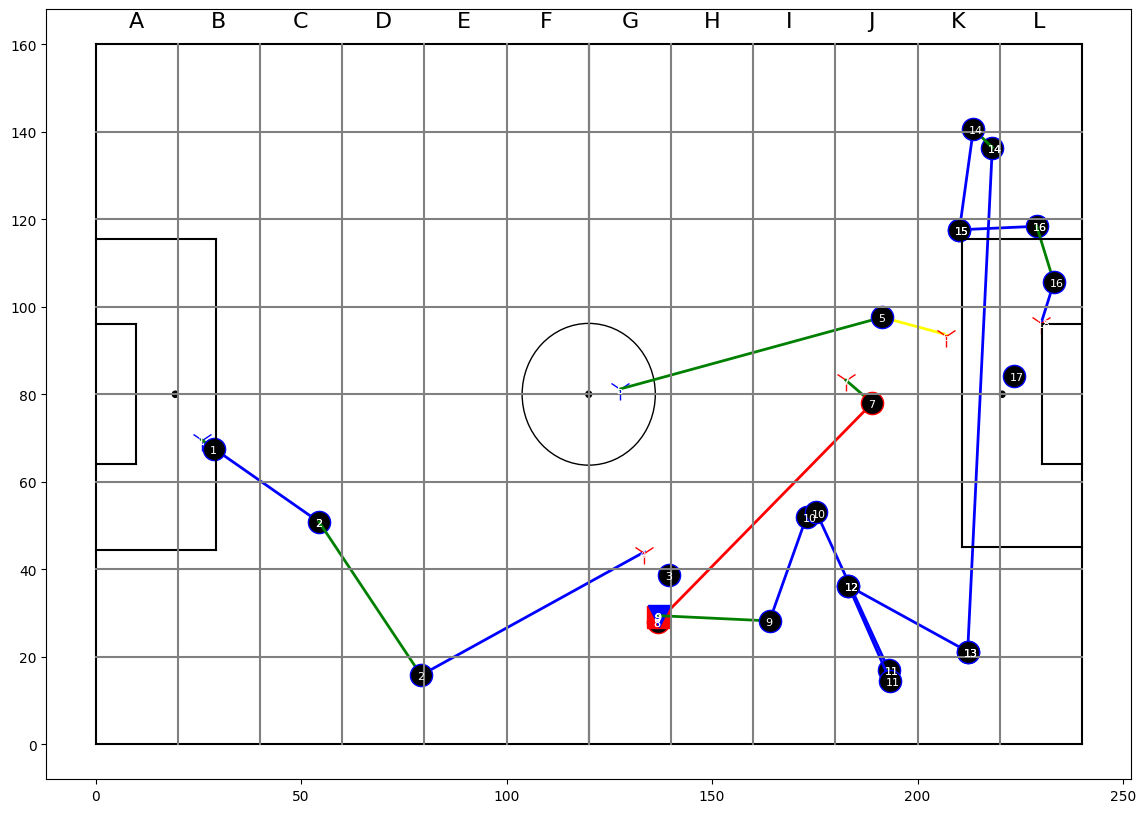

Team: Poland
1: Robert Lewandowski (Pass) <00:14:27.949>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:14:28.657>
2: Mateusz Andrzej Klich (Pass) <00:14:28.704>
3: Grzegorz Krychowiak (Ball Receipt*) <00:14:29.569>
3: Grzegorz Krychowiak (Carry) <00:14:29.569>
3: Grzegorz Krychowiak (Pass) <00:14:31.228>
4: Jan Bednarek (Ball Receipt*) <00:14:32.305>
4: Jan Bednarek (Carry) <00:14:32.305>
4: Jan Bednarek (Pass) <00:14:33.116>
5: Bartosz Bereszyński (Ball Receipt*) <00:14:34.375>
5: Bartosz Bereszyński (Carry) <00:14:34.375>
5: Bartosz Bereszyński (Pass) <00:14:36.171>
6: Kamil Jóźwiak (Ball Receipt*) <00:14:37.447>
6: Kamil Jóźwiak (Carry) <00:14:37.447>
6: Kamil Jóźwiak (Pass) <00:14:38.357>
7: Piotr Zieliński (Ball Receipt*) <00:14:39.336>
7: Piotr Zieliński (Carry) <00:14:39.336>
7: Piotr Zieliński (Dribble) <00:14:41.137>
7: Piotr Zieliński (Carry) <00:14:41.137>
7: Piotr Zieliński (Pass) <00:14:45.214>
8: Mateusz Andrzej Klich (Ball Receipt*) <00:14:46.029>
8: Mateusz Andrzej Klich

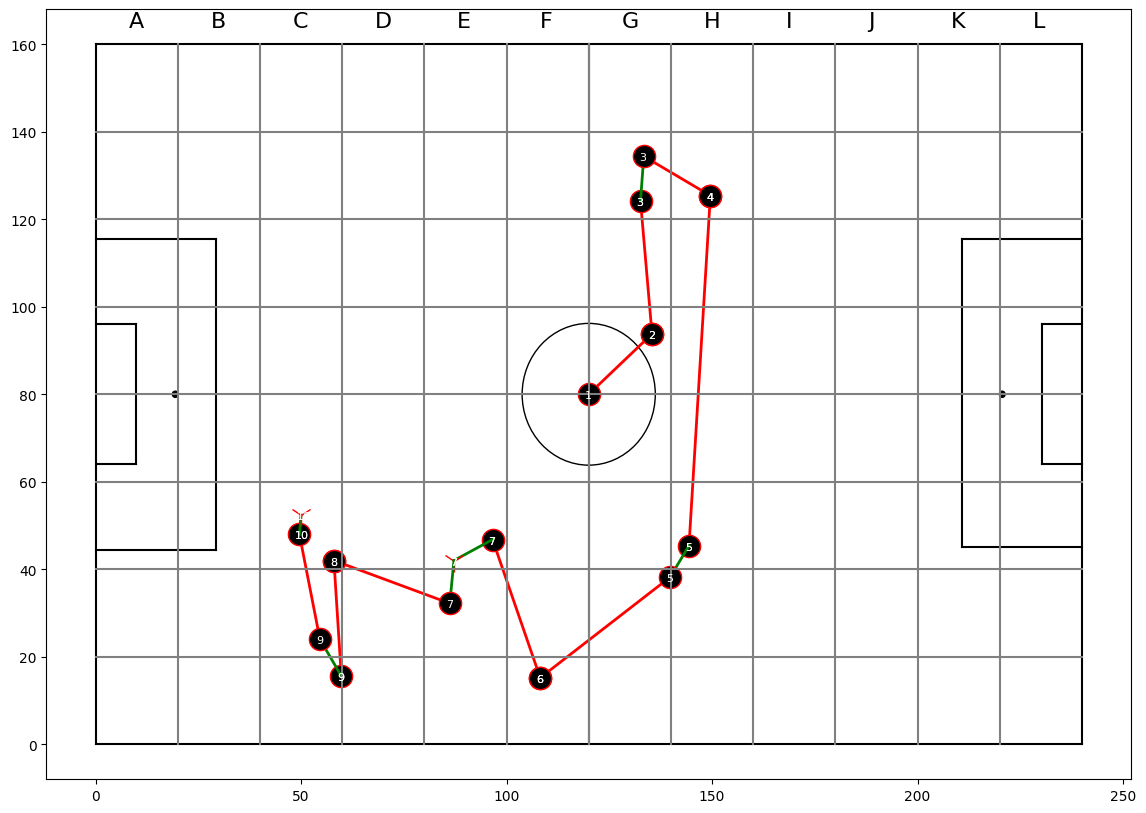

Team: Poland
1: Jan Bednarek (Duel) <00:16:14.413>
2: Przemysław Frankowski (Ball Recovery) <00:16:15.671>
2: Przemysław Frankowski (Carry) <00:16:15.671>
2: Przemysław Frankowski (Pass) <00:16:16.477>
3: Jan Bednarek (Ball Receipt*) <00:16:17.273>
3: Jan Bednarek (Carry) <00:16:17.273>
3: Jan Bednarek (Pass) <00:16:18.047>
4: Grzegorz Krychowiak (Ball Receipt*) <00:16:18.912>
4: Grzegorz Krychowiak (Carry) <00:16:18.912>
4: Grzegorz Krychowiak (Pass) <00:16:19.425>
5: Przemysław Frankowski (Ball Receipt*) <00:16:20.951>
5: Przemysław Frankowski (Carry) <00:16:20.951>
5: Przemysław Frankowski (Pass) <00:16:26.572>
6: Piotr Zieliński (Ball Receipt*) <00:16:27.457>
6: Piotr Zieliński (Carry) <00:16:27.457>
6: Piotr Zieliński (Pass) <00:16:32.448>
7: Karol Świderski (Ball Receipt*) <00:16:34.715>
7: Karol Świderski (Carry) <00:16:34.715>
7: Karol Świderski (Pass) <00:16:37.367>
8: Marcus Andreas Danielsson (Clearance) <00:16:38.063>
9: Piotr Zieliński (Ball Recovery) <00:16:38.692>
9: Pio

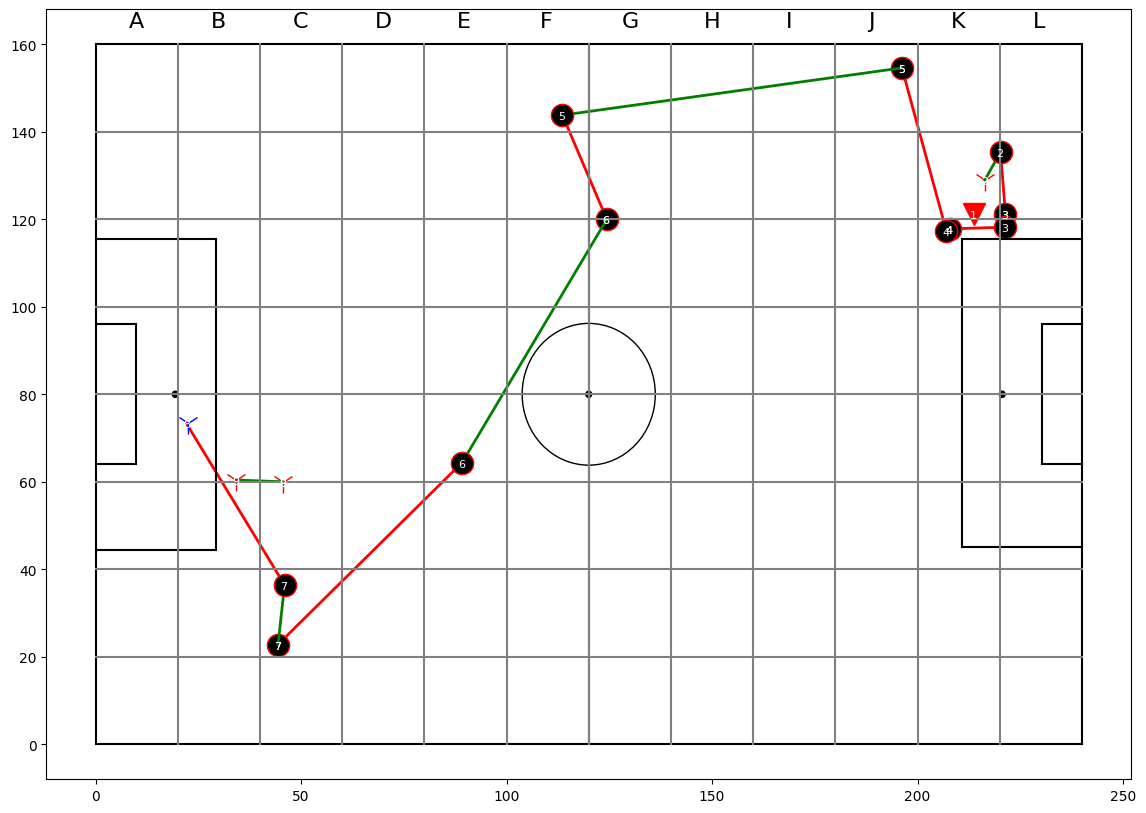

Team: Poland
1: Mateusz Andrzej Klich (Pass) <00:17:54.177>
2: Przemysław Frankowski (Ball Receipt*) <00:17:56.574>
2: Przemysław Frankowski (Carry) <00:17:56.574>
2: Przemysław Frankowski (Pass) <00:17:57.972>
3: Grzegorz Krychowiak (Ball Receipt*) <00:17:58.917>
3: Grzegorz Krychowiak (Carry) <00:17:58.917>
3: Grzegorz Krychowiak (Pass) <00:18:00.397>
4: Bartosz Bereszyński (Ball Receipt*) <00:18:02.213>
4: Bartosz Bereszyński (Carry) <00:18:02.213>
4: Bartosz Bereszyński (Pass) <00:18:05.020>
5: Karol Świderski (Ball Receipt*) <00:18:06.741>
5: Karol Świderski (Carry) <00:18:06.741>
5: Karol Świderski (Pass) <00:18:09.893>
6: Kamil Glik (Ball Receipt*) <00:18:11.475>
6: Kamil Glik (Carry) <00:18:11.475>
6: Kamil Glik (Pass) <00:18:12.532>
7: Jan Bednarek (Ball Receipt*) <00:18:13.678>
7: Jan Bednarek (Carry) <00:18:13.678>
7: Jan Bednarek (Pass) <00:18:16.072>
8: Bartosz Bereszyński (Ball Receipt*) <00:18:17.384>
8: Bartosz Bereszyński (Carry) <00:18:17.384>
8: Bartosz Bereszyński (

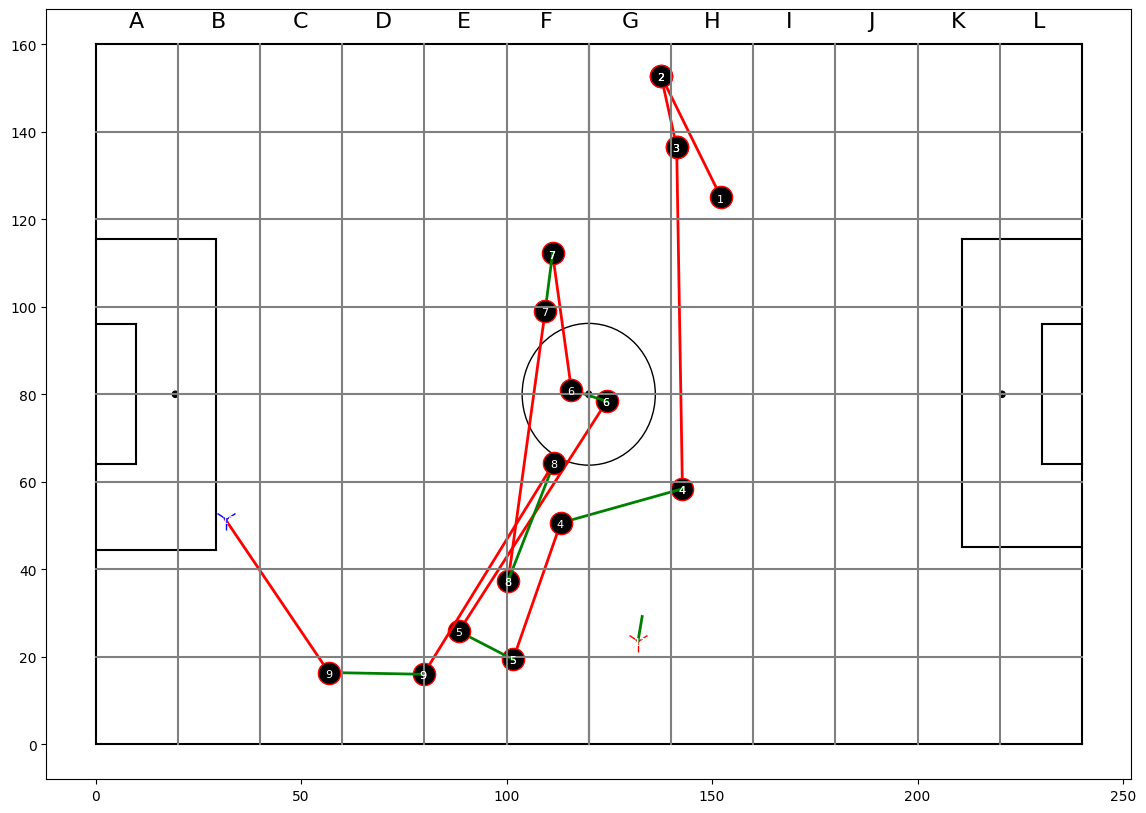

Team: Poland
1: Dejan Kulusevski (Foul Committed) <00:18:34.137>
2: Bartosz Bereszyński (Foul Won) <00:18:34.137>
2: Bartosz Bereszyński (Carry) <00:18:34.137>
2: Bartosz Bereszyński (Pass) <00:18:36.991>
3: Karol Świderski (Ball Receipt*) <00:18:38.043>
3: Karol Świderski (Carry) <00:18:38.043>
3: Karol Świderski (Pass) <00:18:43.445>
4: Grzegorz Krychowiak (Ball Receipt*) <00:18:44.443>
4: Grzegorz Krychowiak (Carry) <00:18:44.443>
4: Grzegorz Krychowiak (Shot) <00:18:45.572>
5: Sebastian Larsson (Block) <00:18:45.647>
6: Przemysław Frankowski (Ball Recovery) <00:18:47.663>
6: Przemysław Frankowski (Carry) <00:18:47.663>
6: Przemysław Frankowski (Pass) <00:18:49.891>
7: Sebastian Larsson (Block) <00:18:50.156>
8: Robin Olsen (Ball Recovery) <00:18:51.552>
8: Robin Olsen (Carry) <00:18:51.552>
8: Robin Olsen (Pass) <00:19:10.118>
9: Alexander Isak (Ball Receipt*) <00:19:14.347>
9: Alexander Isak (Duel) <00:19:14.347>
10: Jan Bednarek (Pass) <00:19:14.347>
11: Jakub Świerczok (Ball Rec

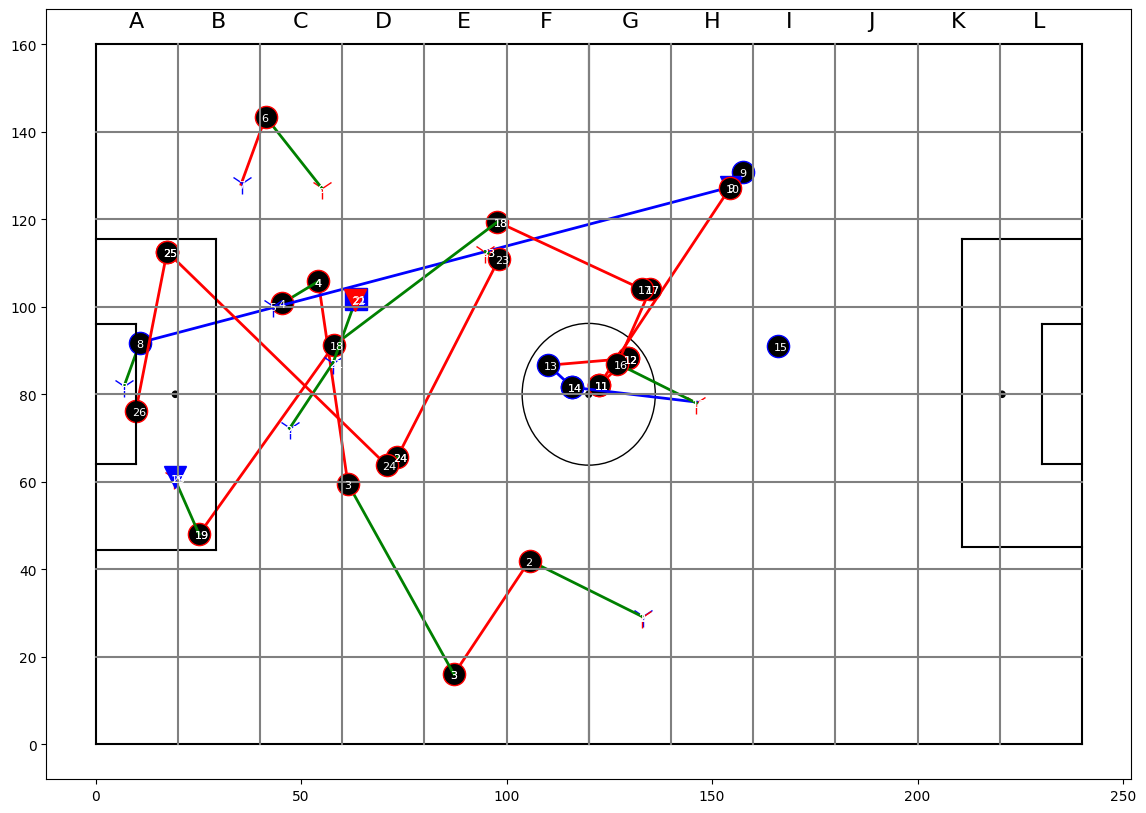

Team: Poland
1: Piotr Zieliński (Ball Recovery) <00:21:32.143>
1: Piotr Zieliński (Carry) <00:21:32.143>
1: Piotr Zieliński (Pass) <00:21:38.036>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:21:39.229>
2: Mateusz Andrzej Klich (Carry) <00:21:39.229>
2: Mateusz Andrzej Klich (Pass) <00:21:41.473>
3: Karol Świderski (Ball Receipt*) <00:21:42.587>
3: Karol Świderski (Carry) <00:21:42.587>
3: Karol Świderski (Pass) <00:21:44.720>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:21:45.868>
4: Mateusz Andrzej Klich (Carry) <00:21:45.868>
4: Mateusz Andrzej Klich (Pass) <00:21:46.618>
5: Bartosz Bereszyński (Ball Receipt*) <00:21:47.142>
5: Bartosz Bereszyński (Carry) <00:21:47.142>
5: Bartosz Bereszyński (Pass) <00:21:50.096>
6: Mateusz Andrzej Klich (Ball Receipt*) <00:21:51.374>
6: Mateusz Andrzej Klich (Carry) <00:21:51.374>
6: Mateusz Andrzej Klich (Pass) <00:21:53.404>
7: Marcus Andreas Danielsson (Clearance) <00:21:55.292>
8: Sebastian Larsson (Pass) <00:21:57.172>
9: Alexander Isak (Ball 

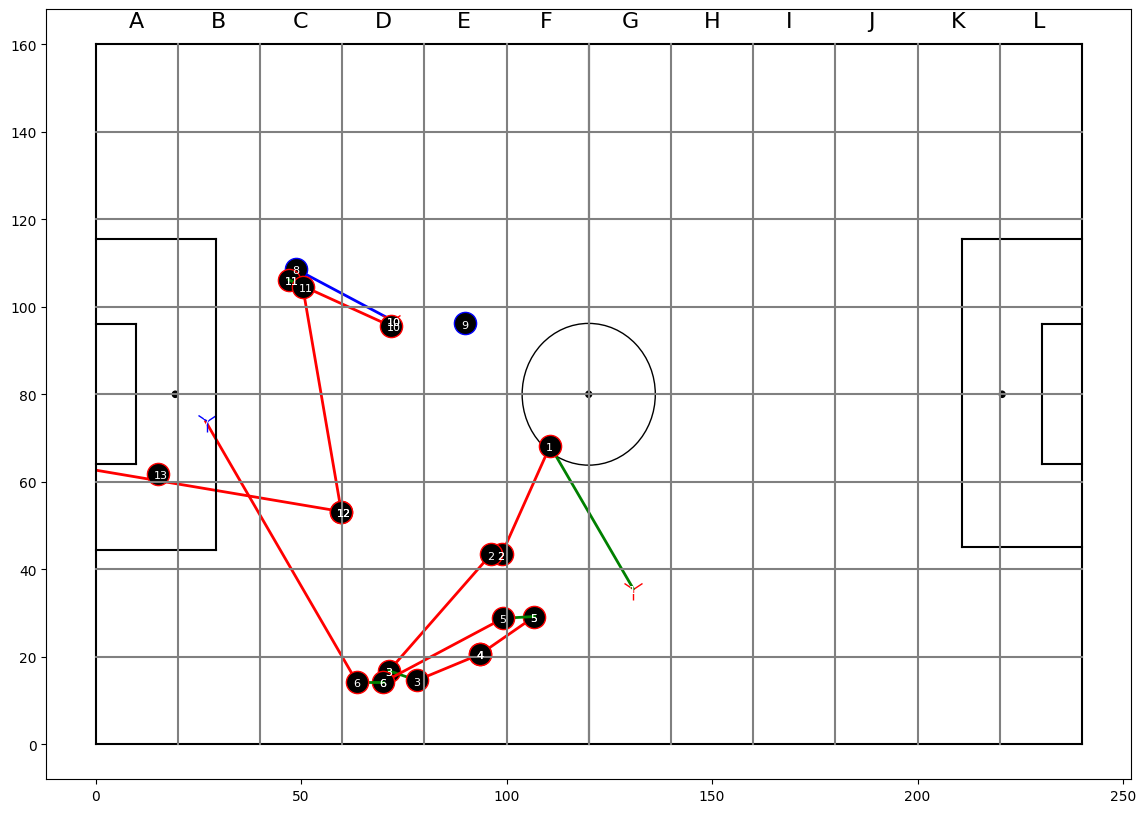

Team: Poland
1: Kamil Glik (Pass) <00:27:30.920>
2: Jan Bednarek (Ball Receipt*) <00:27:31.520>
2: Jan Bednarek (Pass) <00:27:32.130>
3: Kamil Glik (Ball Receipt*) <00:27:33.303>
3: Kamil Glik (Pass) <00:27:34.880>
4: Bartosz Bereszyński (Ball Receipt*) <00:27:36.518>
4: Bartosz Bereszyński (Carry) <00:27:36.518>
4: Bartosz Bereszyński (Pass) <00:27:37.655>
5: Karol Świderski (Ball Receipt*) <00:27:39.080>
5: Karol Świderski (Pass) <00:27:39.080>
6: Bartosz Bereszyński (Ball Receipt*) <00:27:40.144>
6: Bartosz Bereszyński (Carry) <00:27:40.144>
6: Bartosz Bereszyński (Pass) <00:27:43.571>
7: Piotr Zieliński (Ball Receipt*) <00:27:46.328>
8: Marcus Andreas Danielsson (Clearance) <00:27:46.328>
9: Kristoffer Olsson (Duel) <00:27:48.485>
10: Grzegorz Krychowiak (Pass) <00:27:48.485>
11: Emil Krafth (Pass) <00:27:50.220>
12: Marcus Berg (Ball Receipt*) <00:27:52.503>
13: Jan Bednarek (Ball Recovery) <00:27:52.503>
13: Jan Bednarek (Carry) <00:27:52.503>
13: Jan Bednarek (Pass) <00:27:59.87

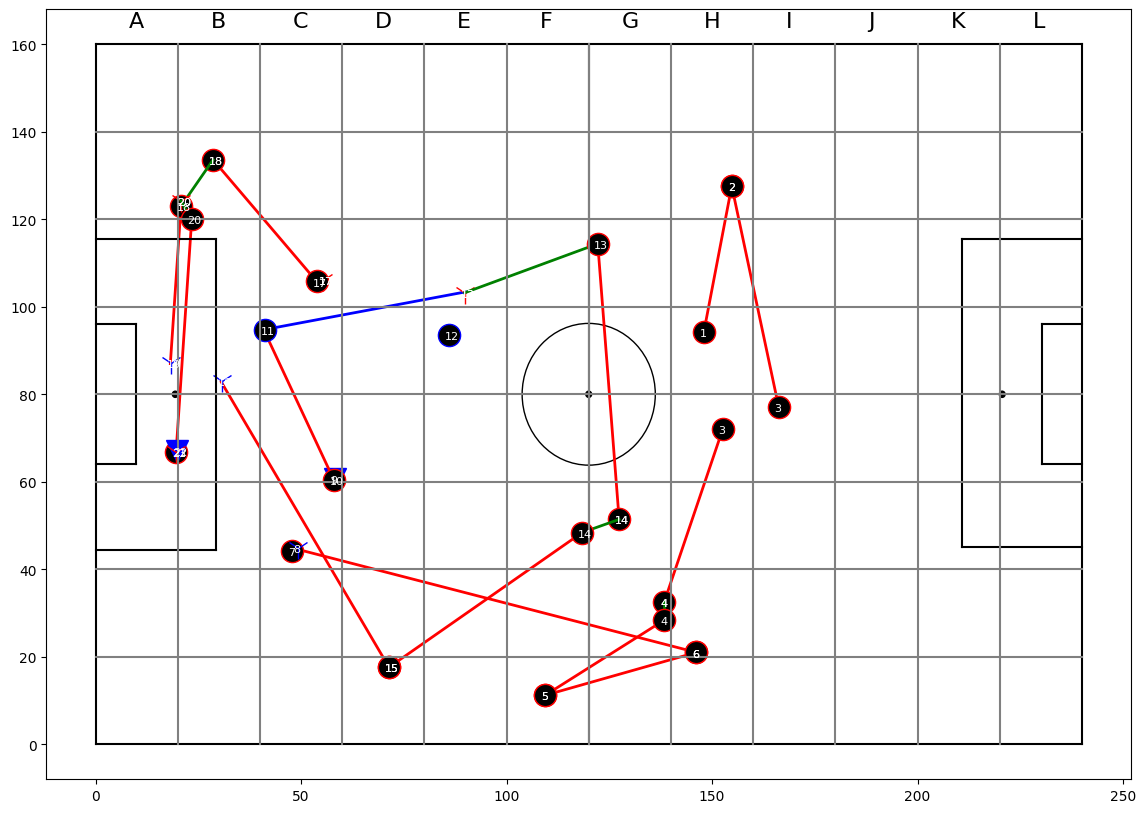

Team: Poland
1: Kamil Glik (Pass) <00:30:31.162>
2: Grzegorz Krychowiak (Ball Receipt*) <00:30:32.389>
2: Grzegorz Krychowiak (Pass) <00:30:32.389>
3: Jan Bednarek (Ball Receipt*) <00:30:33.323>
3: Jan Bednarek (Carry) <00:30:33.323>
3: Jan Bednarek (Pass) <00:30:35.492>
4: Kamil Glik (Ball Receipt*) <00:30:37.036>
4: Kamil Glik (Carry) <00:30:37.036>
4: Kamil Glik (Pass) <00:30:37.961>
5: Bartosz Bereszyński (Ball Receipt*) <00:30:39.082>
5: Bartosz Bereszyński (Carry) <00:30:39.082>
5: Bartosz Bereszyński (Pass) <00:30:40.531>
6: Kacper Kozłowski (Ball Receipt*) <00:30:41.419>
6: Kacper Kozłowski (Carry) <00:30:41.419>
6: Kacper Kozłowski (Pass) <00:30:44.398>
7: Karol Świderski (Ball Receipt*) <00:30:45.405>
7: Karol Świderski (Carry) <00:30:45.405>
7: Karol Świderski (Pass) <00:30:46.674>
8: Bartosz Bereszyński (Ball Receipt*) <00:30:48.989>
9: Marcus Andreas Danielsson (Clearance) <00:30:48.989>
10: Bartosz Bereszyński (Block) <00:30:49.080>
11: Marcus Andreas Danielsson (Block) <

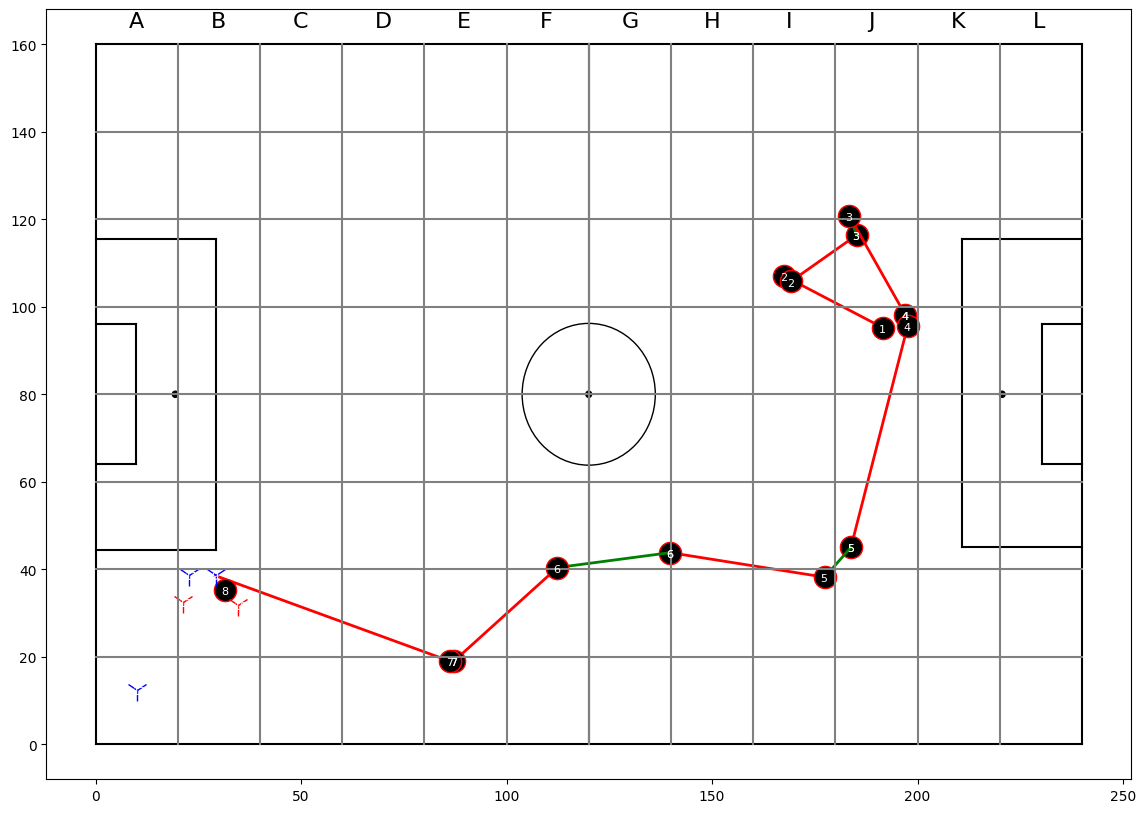

Team: Poland
1: Bartosz Bereszyński (Pass) <00:31:52.965>
2: Kamil Glik (Ball Receipt*) <00:31:53.671>
2: Kamil Glik (Carry) <00:31:53.671>
2: Kamil Glik (Pass) <00:31:55.009>
3: Jan Bednarek (Ball Receipt*) <00:31:56.750>
3: Jan Bednarek (Pass) <00:31:58.560>
4: Przemysław Frankowski (Ball Receipt*) <00:32:00.172>
4: Przemysław Frankowski (Pass) <00:32:02.688>
5: Kamil Glik (Ball Receipt*) <00:32:04.647>
5: Kamil Glik (Carry) <00:32:04.647>
5: Kamil Glik (Pass) <00:32:05.450>
6: Bartosz Bereszyński (Ball Receipt*) <00:32:06.399>
6: Bartosz Bereszyński (Carry) <00:32:06.399>
6: Bartosz Bereszyński (Pass) <00:32:08.844>
7: Karol Świderski (Ball Receipt*) <00:32:10.070>
7: Karol Świderski (Carry) <00:32:10.070>
7: Karol Świderski (Pass) <00:32:11.624>
8: Kamil Glik (Ball Receipt*) <00:32:13.407>
8: Kamil Glik (Carry) <00:32:13.407>
8: Kamil Glik (Pass) <00:32:13.673>
9: Jan Bednarek (Ball Receipt*) <00:32:14.948>
9: Jan Bednarek (Carry) <00:32:14.948>
9: Jan Bednarek (Pass) <00:32:16.396

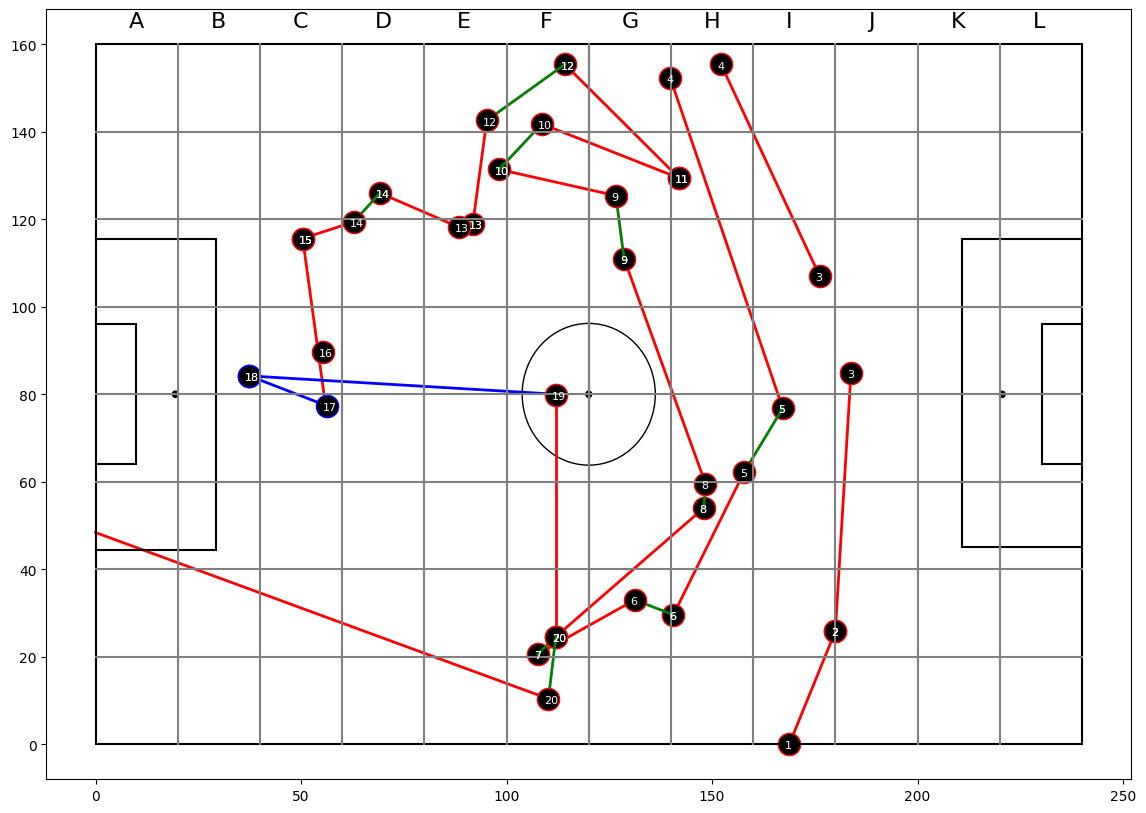

Team: Poland
1: Kamil Glik (Pass) <00:33:16.643>
2: Robert Lewandowski (Ball Receipt*) <00:33:21.280>
2: Robert Lewandowski (Pass) <00:33:22.043>
3: Jakub Świerczok (Ball Receipt*) <00:33:22.808>
3: Jakub Świerczok (Miscontrol) <00:33:22.984>
4: Robin Olsen (Ball Recovery) <00:33:24.088>
4: Robin Olsen (Pass) <00:33:40.804>
5: Viktor Claesson (Ball Receipt*) <00:33:44.299>
5: Viktor Claesson (Pass) <00:33:44.299>
6: Kamil Glik (Duel) <00:33:44.299>
6: Kamil Glik (Block) <00:33:44.334>
7: Piotr Zieliński (Ball Recovery) <00:33:46.684>
7: Piotr Zieliński (Carry) <00:33:46.684>
7: Piotr Zieliński (Dispossessed) <00:33:53.585>
8: Marcus Berg (Duel) <00:33:53.585>
9: Jan Bednarek (Pass) <00:33:55.132>
10: Bartosz Bereszyński (Ball Receipt*) <00:33:56.605>
10: Bartosz Bereszyński (Carry) <00:33:56.605>
10: Bartosz Bereszyński (Pass) <00:33:57.715>
11: Kacper Kozłowski (Ball Receipt*) <00:33:58.396>
11: Kacper Kozłowski (Carry) <00:33:58.396>
11: Kacper Kozłowski (Pass) <00:33:59.439>
12: Prz

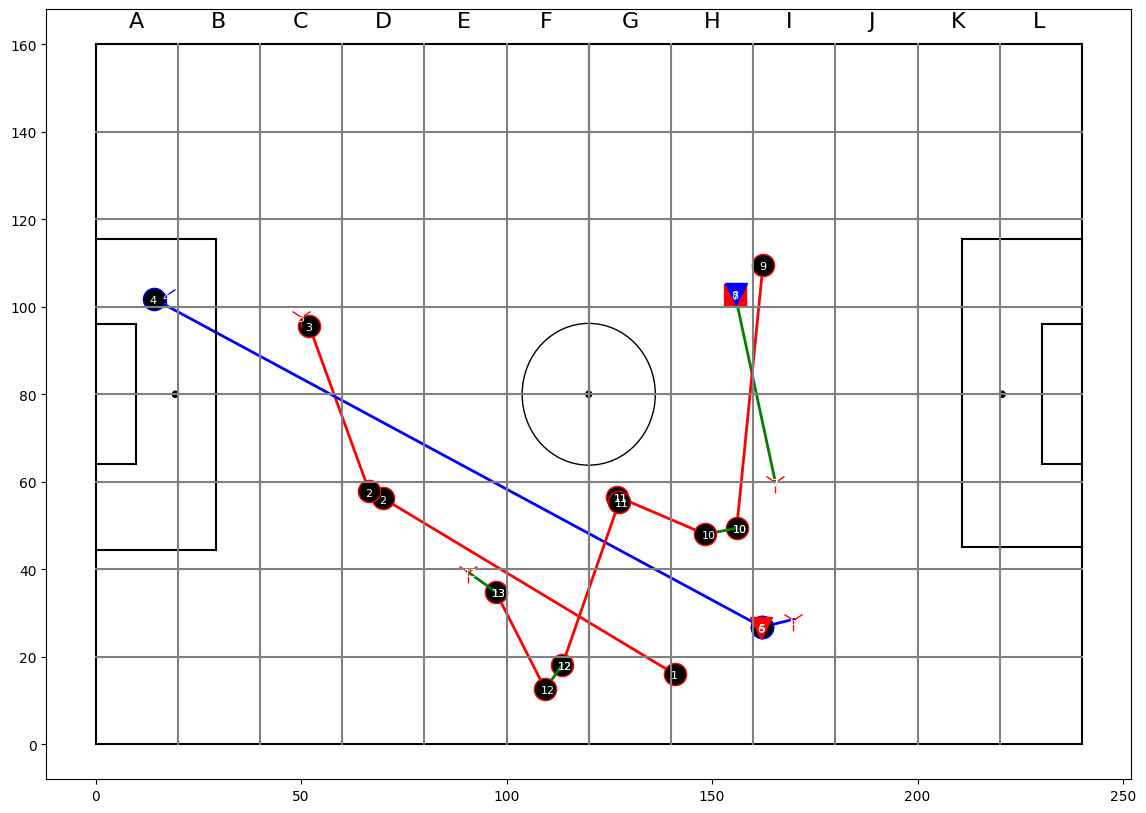

Team: Poland
1: Jan Bednarek (Duel) <00:34:08.390>
1: Jan Bednarek (Carry) <00:34:08.390>
1: Jan Bednarek (Pass) <00:34:09.405>
2: Piotr Zieliński (Ball Receipt*) <00:34:10.289>
2: Piotr Zieliński (Carry) <00:34:10.289>
2: Piotr Zieliński (Pass) <00:34:12.769>
3: Robert Lewandowski (Ball Receipt*) <00:34:14.357>
3: Robert Lewandowski (Carry) <00:34:14.357>
3: Robert Lewandowski (Pass) <00:34:15.938>
4: Przemysław Frankowski (Ball Receipt*) <00:34:17.368>
4: Przemysław Frankowski (Carry) <00:34:17.368>
4: Przemysław Frankowski (Pass) <00:34:20.427>
5: Przemysław Płacheta (Ball Receipt*) <00:34:23.502>
5: Przemysław Płacheta (Carry) <00:34:23.502>
5: Przemysław Płacheta (Pass) <00:34:28.074>
6: Sebastian Larsson (Clearance) <00:34:29.897>
7: Robert Lewandowski (Duel) <00:34:31.303>
8: Victor Nilsson Lindelöf (Clearance) <00:34:31.303>
9: Kristoffer Olsson (Clearance) <00:34:32.077>
10: Dejan Kulusevski (Foul Committed) <00:34:35.490>
11: Jan Bednarek (Foul Won) <00:34:35.490>
11: Jan Bed

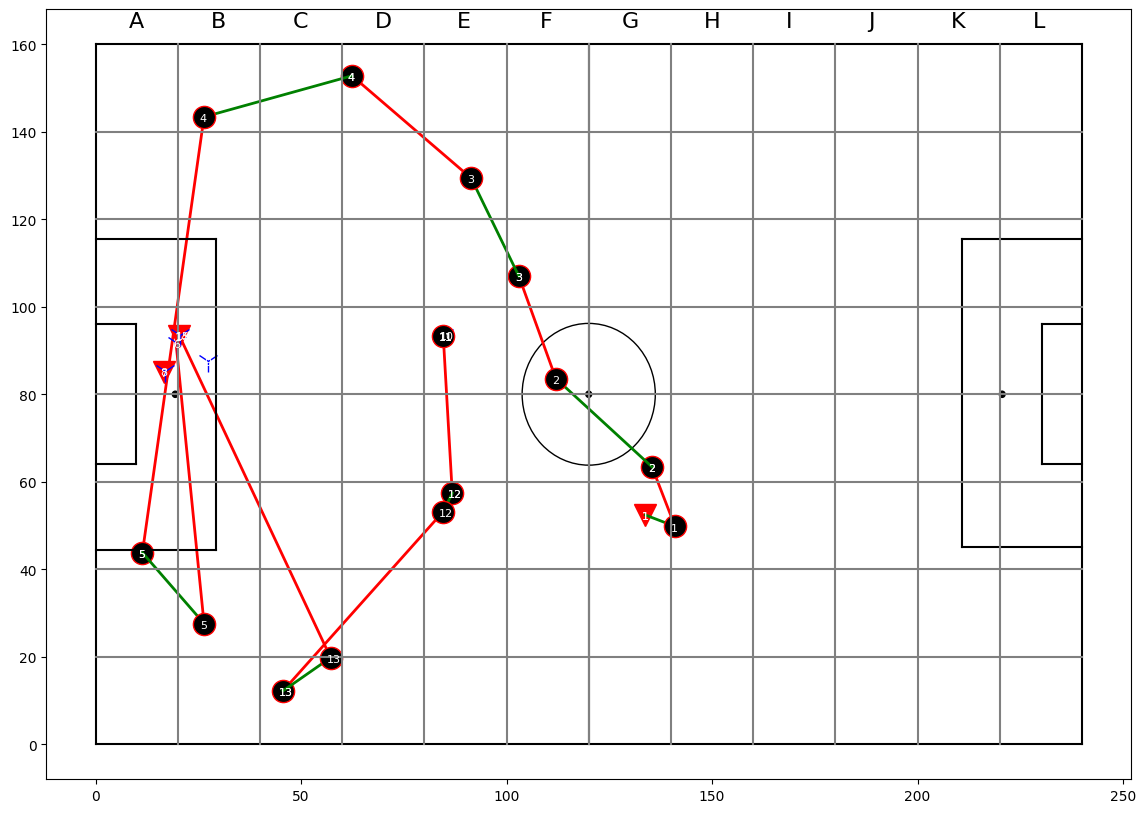

Team: Poland
1: Kamil Glik (Pass) <00:35:54.333>
2: Przemysław Frankowski (Ball Receipt*) <00:35:55.994>
2: Przemysław Frankowski (Carry) <00:35:55.994>
2: Przemysław Frankowski (Pass) <00:35:57.848>
3: Jan Bednarek (Ball Receipt*) <00:35:58.877>
3: Jan Bednarek (Carry) <00:35:58.877>
3: Jan Bednarek (Pass) <00:36:00.268>
4: Bartosz Bereszyński (Ball Receipt*) <00:36:01.708>
4: Bartosz Bereszyński (Carry) <00:36:01.708>
4: Bartosz Bereszyński (Pass) <00:36:02.564>
5: Kacper Kozłowski (Ball Receipt*) <00:36:03.474>
5: Kacper Kozłowski (Pass) <00:36:03.474>
6: Bartosz Bereszyński (Ball Receipt*) <00:36:04.434>
6: Bartosz Bereszyński (Carry) <00:36:04.434>
6: Bartosz Bereszyński (Pass) <00:36:05.518>
7: Kacper Kozłowski (Ball Receipt*) <00:36:06.621>
7: Kacper Kozłowski (Carry) <00:36:06.621>
7: Kacper Kozłowski (Pass) <00:36:07.367>
8: Kamil Glik (Ball Receipt*) <00:36:09.060>
8: Kamil Glik (Carry) <00:36:09.060>
8: Kamil Glik (Pass) <00:36:11.867>
9: Jan Bednarek (Ball Receipt*) <00:36:

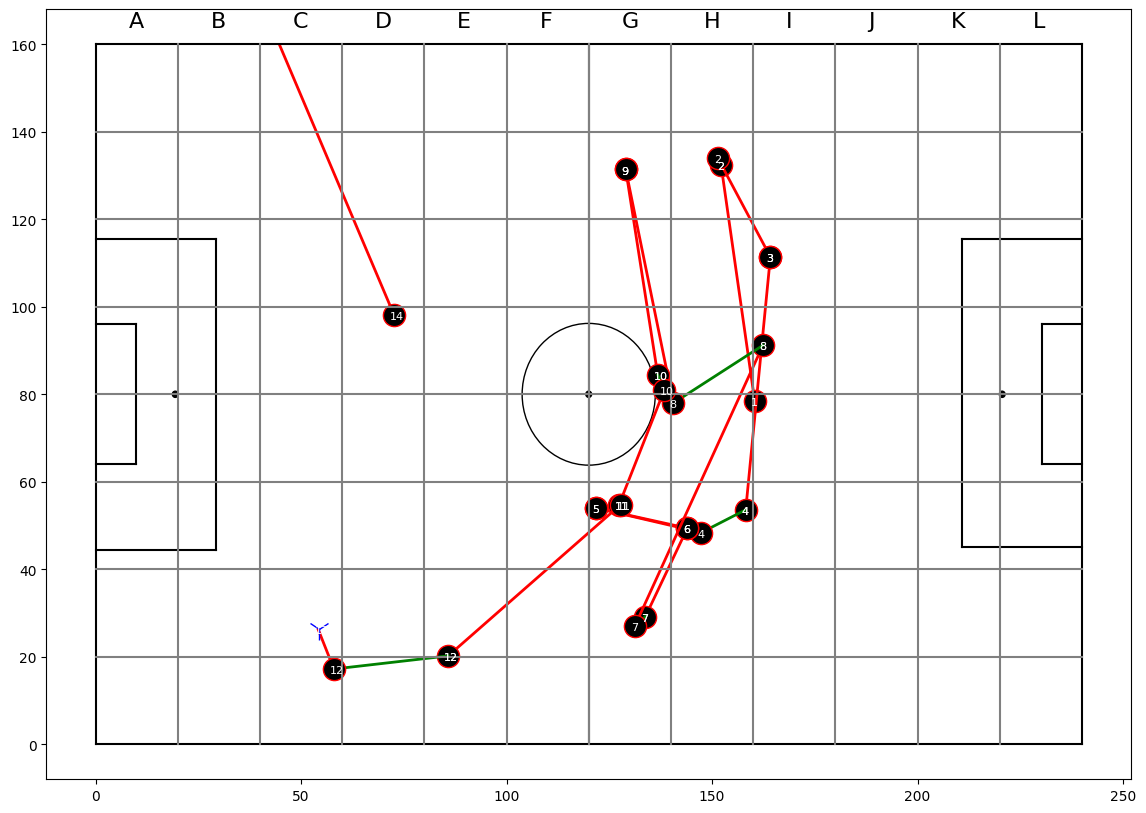

Team: Poland
1: Kacper Kozłowski (Pass) <00:40:00.164>
2: Karol Świderski (Ball Receipt*) <00:40:02.527>
2: Karol Świderski (Carry) <00:40:02.527>
2: Karol Świderski (Dribble) <00:40:07.348>
2: Karol Świderski (Carry) <00:40:07.348>
2: Karol Świderski (Pass) <00:40:08.604>
3: Przemysław Frankowski (Ball Receipt*) <00:40:10.037>
3: Przemysław Frankowski (Carry) <00:40:10.037>
3: Przemysław Frankowski (Pass) <00:40:11.418>
4: Robert Lewandowski (Ball Receipt*) <00:40:12.550>
4: Robert Lewandowski (Carry) <00:40:12.550>
4: Robert Lewandowski (Pass) <00:40:18.493>
5: Przemysław Frankowski (Ball Receipt*) <00:40:19.509>
5: Przemysław Frankowski (Carry) <00:40:19.509>
5: Przemysław Frankowski (Pass) <00:40:20.759>
6: Piotr Zieliński (Ball Receipt*) <00:40:22.245>
6: Piotr Zieliński (Carry) <00:40:22.245>
6: Piotr Zieliński (Pass) <00:40:24.736>
7: Bartosz Bereszyński (Ball Receipt*) <00:40:25.548>
7: Bartosz Bereszyński (Carry) <00:40:25.548>
7: Bartosz Bereszyński (Pass) <00:40:26.506>
8: P

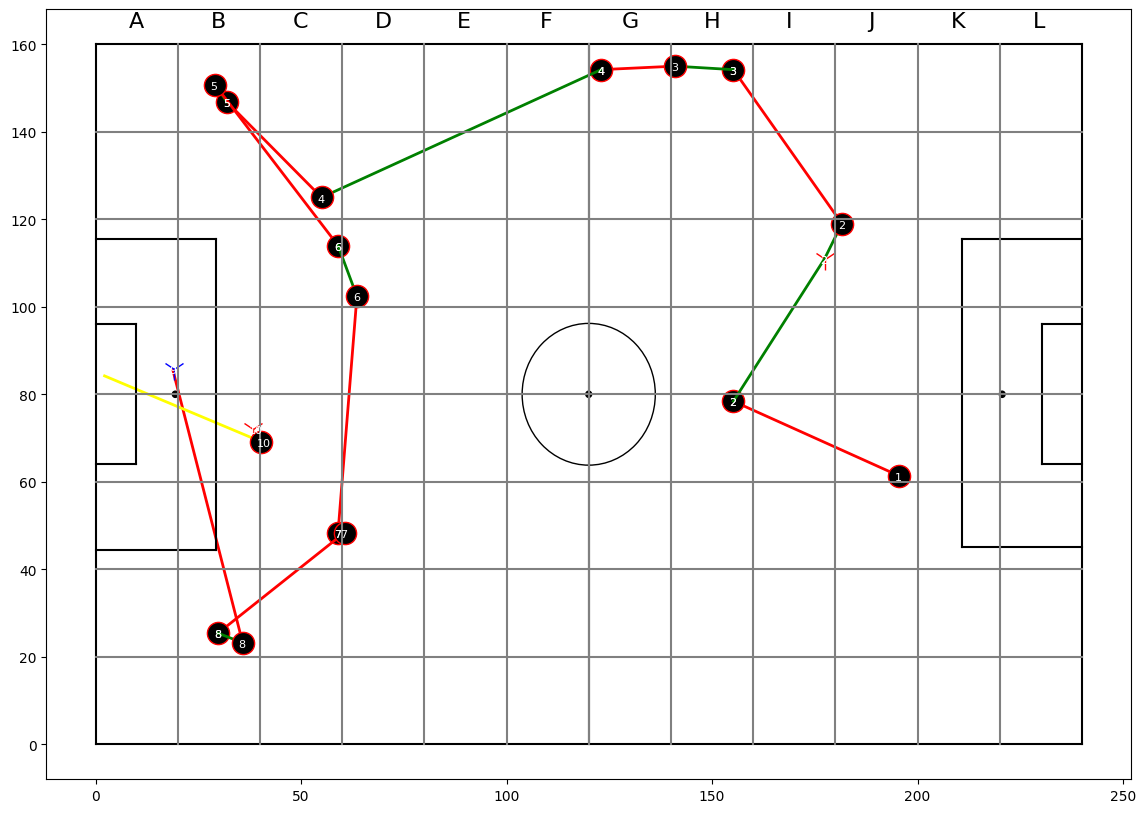

Team: Poland
1: Wojciech Szczęsny (Ball Recovery) <00:40:58.414>
1: Wojciech Szczęsny (Carry) <00:40:58.414>
1: Wojciech Szczęsny (Pass) <00:41:00.752>
2: Jan Bednarek (Ball Receipt*) <00:41:02.125>
2: Jan Bednarek (Carry) <00:41:02.125>
2: Jan Bednarek (Pass) <00:41:06.255>
3: Wojciech Szczęsny (Ball Receipt*) <00:41:09.157>
3: Wojciech Szczęsny (Carry) <00:41:09.157>
3: Wojciech Szczęsny (Pass) <00:41:10.561>
4: Kamil Glik (Ball Receipt*) <00:41:11.448>
4: Kamil Glik (Carry) <00:41:11.448>
4: Kamil Glik (Pass) <00:41:14.386>
5: Bartosz Bereszyński (Ball Receipt*) <00:41:15.605>
5: Bartosz Bereszyński (Carry) <00:41:15.605>
5: Bartosz Bereszyński (Pass) <00:41:16.220>
6: Kacper Kozłowski (Ball Receipt*) <00:41:17.175>
6: Kacper Kozłowski (Pass) <00:41:17.175>
7: Bartosz Bereszyński (Ball Receipt*) <00:41:18.519>
7: Bartosz Bereszyński (Carry) <00:41:18.519>
7: Bartosz Bereszyński (Pass) <00:41:19.010>
8: Przemysław Płacheta (Ball Receipt*) <00:41:20.131>
8: Przemysław Płacheta (Carry)

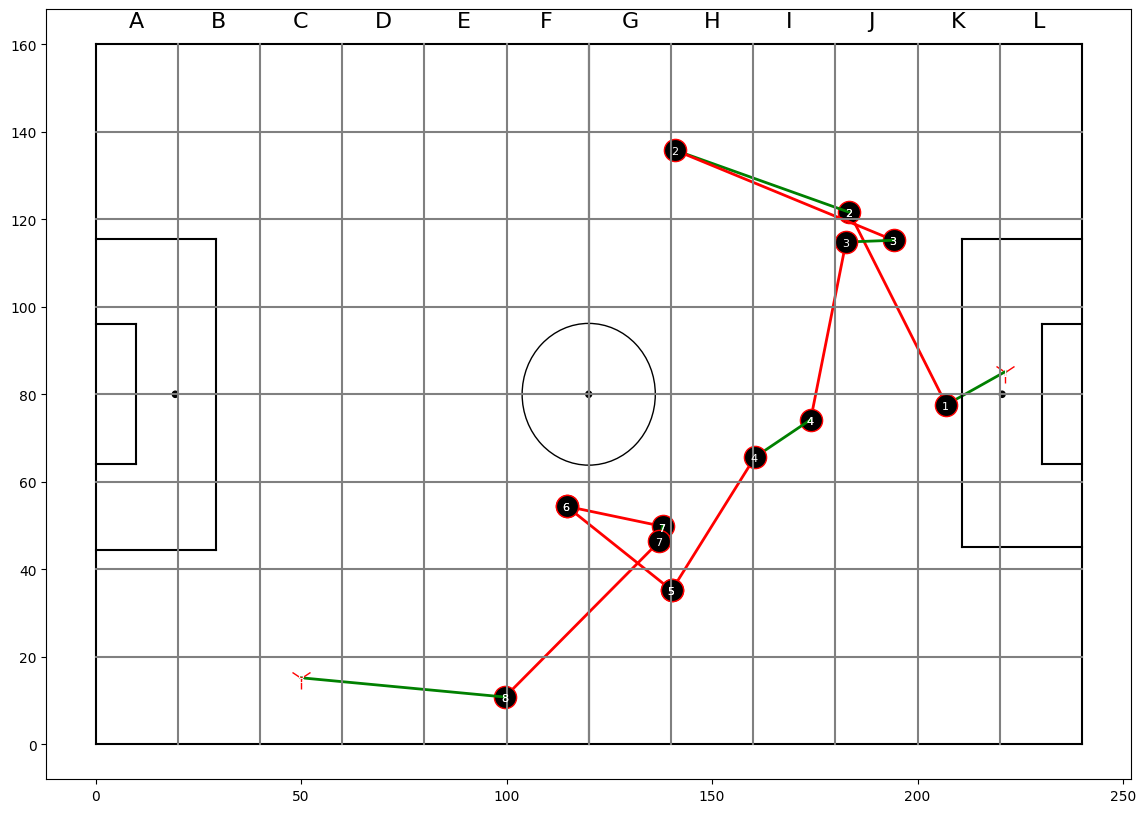

Team: Sweden
1: Bartosz Bereszyński (Foul Committed) <00:41:30.156>
2: Marcus Berg (Foul Won) <00:41:30.156>
3: Marcus Andreas Danielsson (Pass) <00:41:55.634>
4: Viktor Claesson (Ball Receipt*) <00:41:58.303>
4: Viktor Claesson (Pass) <00:41:58.343>
5: Marcus Berg (Ball Receipt*) <00:42:00.151>
5: Marcus Berg (Duel) <00:42:00.151>
6: Bartosz Bereszyński (Pass) <00:42:00.151>
7: Viktor Claesson (Pass) <00:42:01.510>
8: Dejan Kulusevski (Ball Receipt*) <00:42:02.300>
8: Dejan Kulusevski (Carry) <00:42:02.300>
8: Dejan Kulusevski (Pass) <00:42:02.577>
9: Viktor Claesson (Ball Receipt*) <00:42:02.697>
9: Viktor Claesson (Carry) <00:42:02.697>
10: Kamil Glik (Block) <00:42:02.697>
11: Viktor Claesson (Miscontrol) <00:42:03.695>
12: Jan Bednarek (Clearance) <00:42:05.007>
13: Marcus Berg (Ball Recovery) <00:42:06.555>
13: Marcus Berg (Carry) <00:42:06.555>
13: Marcus Berg (Pass) <00:42:07.262>
14: Albin Ekdal (Ball Receipt*) <00:42:07.881>
14: Albin Ekdal (Carry) <00:42:07.881>
14: Albin Ek

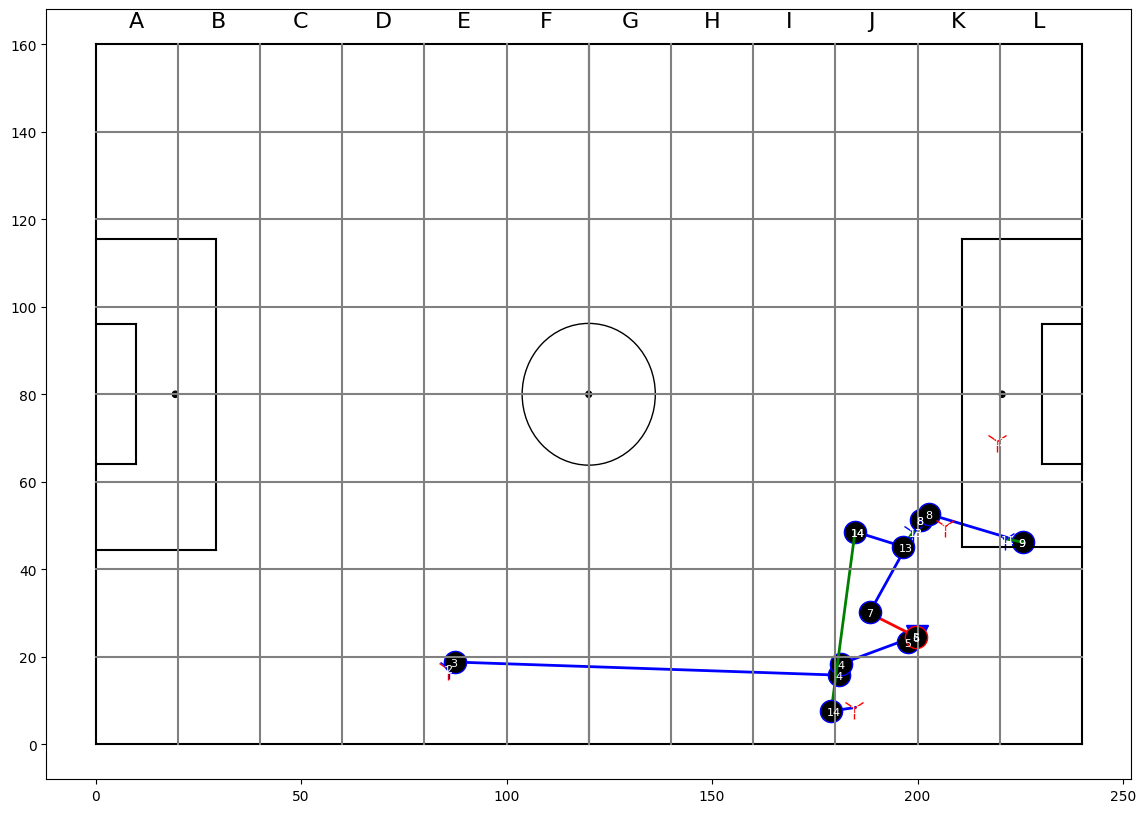

Team: Poland
1: Bartosz Bereszyński (Pass) <00:42:21.776>
2: Przemysław Płacheta (Ball Receipt*) <00:42:22.326>
2: Przemysław Płacheta (Carry) <00:42:22.326>
2: Przemysław Płacheta (Pass) <00:42:23.207>
3: Karol Świderski (Ball Receipt*) <00:42:24.308>
3: Karol Świderski (Carry) <00:42:24.308>
3: Karol Świderski (Miscontrol) <00:42:24.339>
4: Jakub Świerczok (Pass) <00:42:25.103>
5: Karol Świderski (Ball Receipt*) <00:42:25.910>
5: Karol Świderski (Carry) <00:42:25.910>
5: Karol Świderski (Pass) <00:42:27.562>
6: Kacper Kozłowski (Ball Receipt*) <00:42:28.536>
6: Kacper Kozłowski (Carry) <00:42:28.536>
6: Kacper Kozłowski (Pass) <00:42:30.177>
7: Robert Lewandowski (Ball Receipt*) <00:42:34.394>
7: Robert Lewandowski (Carry) <00:42:34.394>
7: Robert Lewandowski (Pass) <00:42:37.332>
8: Jakub Świerczok (Ball Receipt*) <00:42:39.001>
9: Marcus Andreas Danielsson (Clearance) <00:42:39.001>
10: Albin Ekdal (Ball Recovery) <00:42:41.406>
11: Piotr Zieliński (Ball Recovery) <00:42:41.724>
11

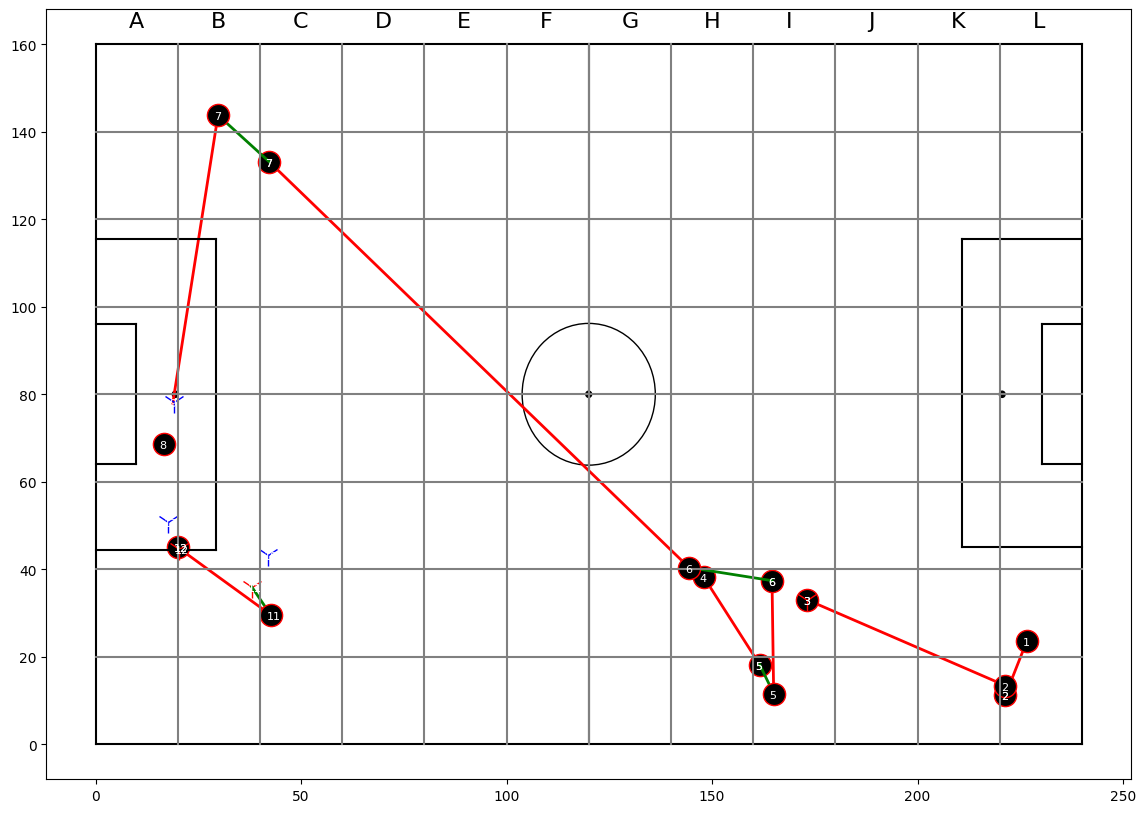

Team: Poland
1: Bartosz Bereszyński (Pass) <00:42:52.871>
2: Przemysław Płacheta (Ball Receipt*) <00:42:53.870>
2: Przemysław Płacheta (Carry) <00:42:53.870>
2: Przemysław Płacheta (Pass) <00:42:54.563>
3: Bartosz Bereszyński (Ball Receipt*) <00:42:55.694>
3: Bartosz Bereszyński (Carry) <00:42:55.694>
3: Bartosz Bereszyński (Pass) <00:42:57.937>
4: Robert Lewandowski (Ball Receipt*) <00:43:01.061>
4: Robert Lewandowski (Carry) <00:43:01.061>
4: Robert Lewandowski (Pass) <00:43:02.658>
5: Przemysław Frankowski (Ball Receipt*) <00:43:03.886>
5: Przemysław Frankowski (Carry) <00:43:03.886>
5: Przemysław Frankowski (Pass) <00:43:05.003>
6: Sebastian Larsson (Block) <00:43:05.086>
7: Przemysław Frankowski (Pass) <00:43:07.351>
8: Jan Bednarek (Ball Receipt*) <00:43:08.558>
8: Jan Bednarek (Carry) <00:43:08.558>
8: Jan Bednarek (Pass) <00:43:09.537>
9: Przemysław Frankowski (Ball Receipt*) <00:43:10.722>
9: Przemysław Frankowski (Carry) <00:43:10.722>
9: Przemysław Frankowski (Pass) <00:43:1

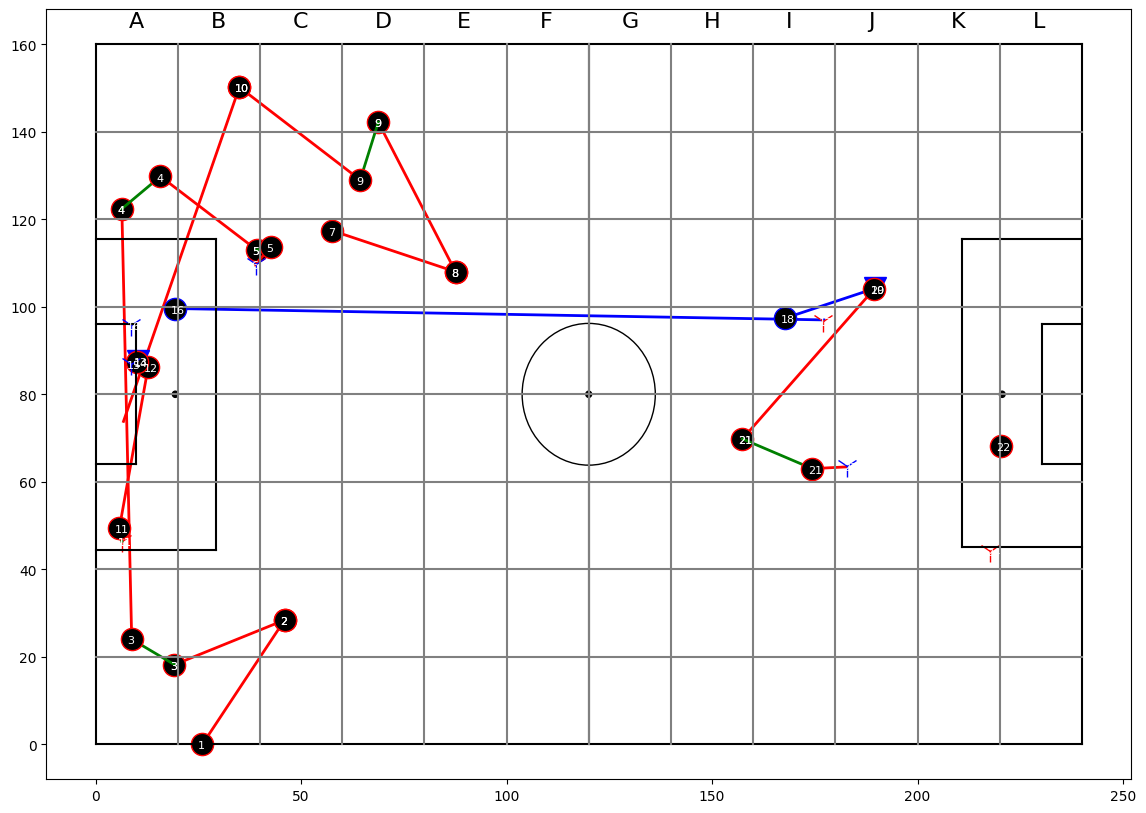

Team: Poland
1: Bartosz Bereszyński (Duel) <00:44:12.659>
1: Bartosz Bereszyński (Carry) <00:44:12.659>
1: Bartosz Bereszyński (Pass) <00:44:15.482>
2: Przemysław Płacheta (Ball Receipt*) <00:44:16.791>
2: Przemysław Płacheta (Carry) <00:44:16.791>
2: Przemysław Płacheta (Pass) <00:44:19.692>
3: Ludwig Augustinsson (Block) <00:44:19.815>
4: Przemysław Frankowski (Pass) <00:44:22.283>
5: Piotr Zieliński (Ball Receipt*) <00:44:23.636>
5: Piotr Zieliński (Pass) <00:44:23.733>
6: Jan Bednarek (Ball Receipt*) <00:44:24.629>
6: Jan Bednarek (Carry) <00:44:24.629>
6: Jan Bednarek (Pass) <00:44:25.977>
7: Robert Lewandowski (Ball Receipt*) <00:44:28.017>
7: Robert Lewandowski (Carry) <00:44:28.017>
7: Robert Lewandowski (Pass) <00:44:32.772>
8: Bartosz Bereszyński (Ball Receipt*) <00:44:34.149>
8: Bartosz Bereszyński (Carry) <00:44:34.149>
8: Bartosz Bereszyński (Pass) <00:44:36.116>
9: Przemysław Płacheta (Ball Receipt*) <00:44:37.396>
9: Przemysław Płacheta (Carry) <00:44:37.396>
9: Przemysł

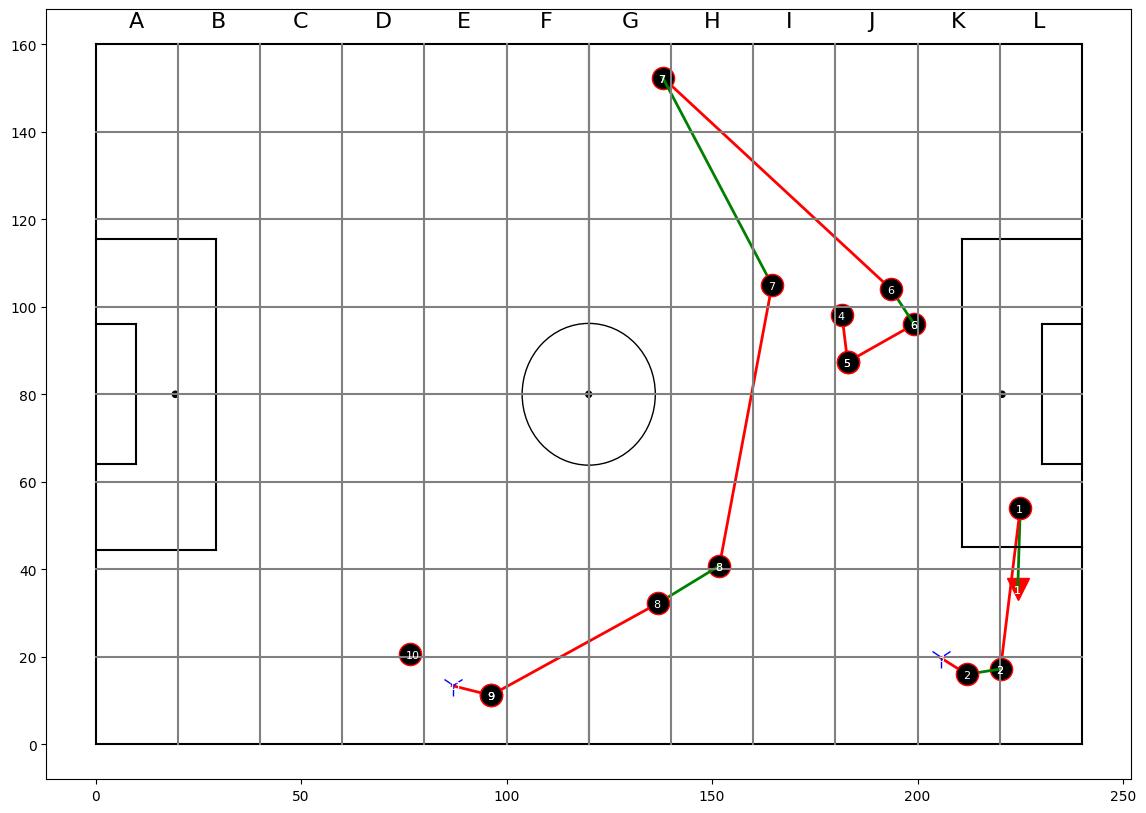

Team: Poland
1: Bartosz Bereszyński (Pass) <00:44:46.904>
2: Jakub Świerczok (Ball Receipt*) <00:44:47.790>
2: Jakub Świerczok (Carry) <00:44:47.790>
2: Jakub Świerczok (Dribble) <00:44:50.172>
2: Jakub Świerczok (Carry) <00:44:50.172>
2: Jakub Świerczok (Pass) <00:44:51.297>
3: Kacper Kozłowski (Ball Receipt*) <00:44:52.388>
3: Kacper Kozłowski (Pass) <00:44:52.388>
4: Marcus Andreas Danielsson (Pass) <00:44:53.538>
5: Viktor Claesson (Ball Receipt*) <00:44:54.680>
5: Viktor Claesson (Pass) <00:44:54.680>
6: Kacper Kozłowski (Block) <00:44:54.975>
7: Viktor Claesson (Clearance) <00:44:55.931>
8: Wojciech Szczęsny (Ball Recovery) <00:45:02.633>
8: Wojciech Szczęsny (Carry) <00:45:02.633>
8: Wojciech Szczęsny (Pass) <00:45:04.662>
9: Jan Bednarek (Ball Receipt*) <00:45:06.745>
9: Jan Bednarek (Carry) <00:45:06.745>
9: Jan Bednarek (Pass) <00:45:08.719>
10: Przemysław Frankowski (Ball Receipt*) <00:45:11.954>
10: Przemysław Frankowski (Carry) <00:45:11.954>
10: Przemysław Frankowski (Pas

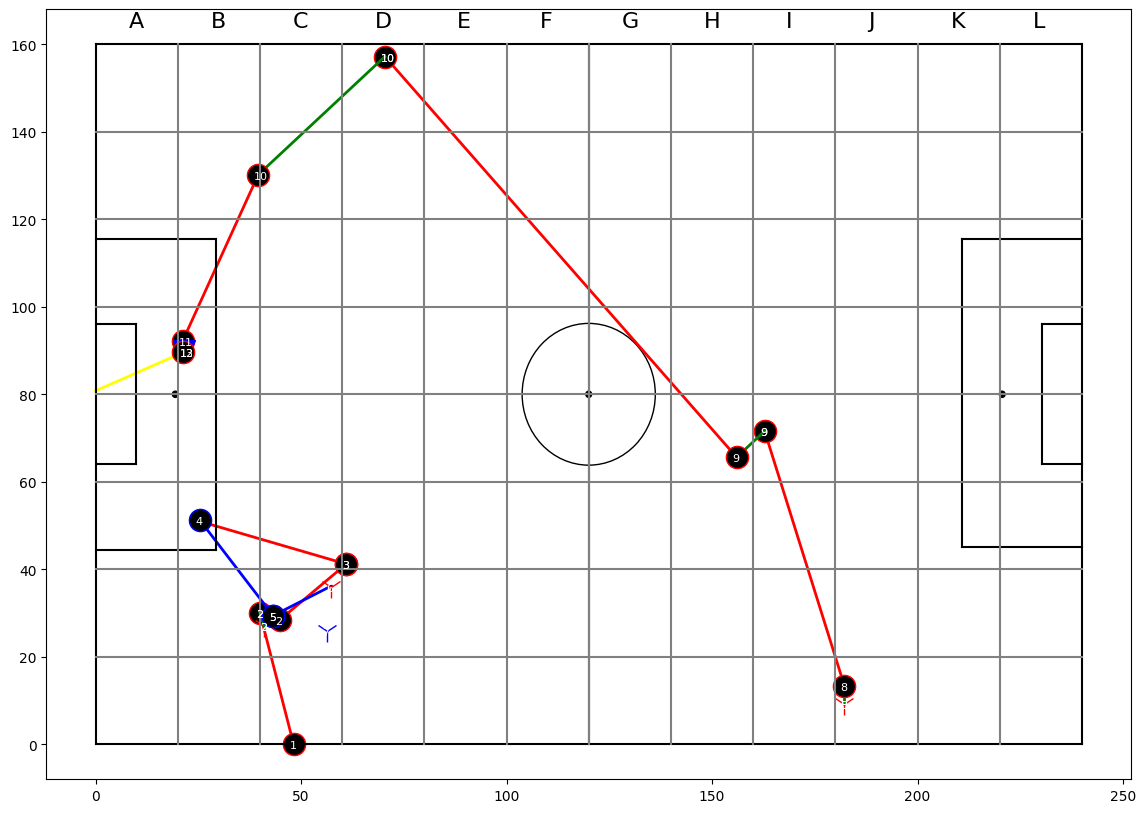

In [7]:
# from draw.draw_sequences import draw_events_sequence

# start_team = merged_events['possession_team'][0]

# for i, s in enumerate(sequences):
#     print(f'Sequence: {i+1}')
#     draw_events_sequence(s, start_team, 12, 8, scale=2)

from draw.draw_sequences import draw_events_sequence

start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    if len(s) > 20:
        draw_events_sequence(s, start_team, 12, 8, scale=2)